<a href="https://colab.research.google.com/github/alexgufron-unnes/Client-Process-Overhead-of-Classical-and-Hybrid-Post-Quantum-Key-Agreement-in-a-Loopback-TLS-Pilot/blob/main/Benchmark_TLS_PQC_Hyperlinked.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Manuscript citation and data access note
The companion manuscript uses blue IEEE hyperlinks from every numbered citation to its reference-list entry. The dataset repository and this notebook are displayed as direct URL hyperlinks in Data Availability, not as numbered IEEE citations. This editorial revision does not change code, archived observations, or results.

Dataset: https://github.com/alexgufron-unnes/Client-Process-Overhead-of-Classical-and-Hybrid-Post-Quantum-Key-Agreement-in-a-Loopback-TLS-Pilot

Current notebook: https://github.com/alexgufron-unnes/Client-Process-Overhead-of-Classical-and-Hybrid-Post-Quantum-Key-Agreement-in-a-Loopback-TLS-Pilot/blob/main/benchmark_tls_pqc_reviewer_final.ipynb


# Client Process Overhead of Classical and Hybrid Post Quantum Key Agreement in a Loopback TLS Pilot

Alex Gufron, Alamsyah, Nizirwan Anwar, Much Aziz Muslim

Run all cells in order. The default replays **60 real archived measurements**. It does not generate replacement data. The main estimate is the difference of group medians, with a pointwise independent two-sample bootstrap interval. All observations remain in the primary analysis.

An optional second path collects a **new, separately labelled runtime session** with randomized group/observer blocks and a C/OpenSSL internal handshake timer. A local two-block smoke test validated that collector; those test values do not enter the paper. Three loop iterations are not three independent runtime sessions.


## Public dataset and code

Repository: [https://github.com/alexgufron-unnes/Client-Process-Overhead-of-Classical-and-Hybrid-Post-Quantum-Key-Agreement-in-a-Loopback-TLS-Pilot](https://github.com/alexgufron-unnes/Client-Process-Overhead-of-Classical-and-Hybrid-Post-Quantum-Key-Agreement-in-a-Loopback-TLS-Pilot).

The [sanitized reproducibility ZIP](https://github.com/alexgufron-unnes/Client-Process-Overhead-of-Classical-and-Hybrid-Post-Quantum-Key-Agreement-in-a-Loopback-TLS-Pilot/blob/main/TLS_PQC_Reviewer_Reproducibility.zip) contains the 60 archived records analyzed here. The [original archive](https://github.com/alexgufron-unnes/Client-Process-Overhead-of-Classical-and-Hybrid-Post-Quantum-Key-Agreement-in-a-Loopback-TLS-Pilot/blob/main/hasil_benchmark_tls_pqc.zip) is also published. Both repository blob hashes match the local source artifacts used for the manuscript.

Sanitized ZIP Git blob SHA: `294fa9b2e1c62b2f9eef538340ca278453de07ae`. SHA-256: `a1a2bbfe22c2cd8be9ebed8f8152abf848858c722419cde247fcc747a5466009`. Verified 6 November 2026. A GitHub URL is public access, not a registered dataset DOI. The embedded records below remain the reproducible default; no new scientific session has been added.


In [1]:
from pathlib import Path
import sys, subprocess, importlib.util, json, base64, hashlib
needed = {'numpy':'numpy>=1.26,<3','pandas':'pandas>=2,<3','matplotlib':'matplotlib>=3.8,<4','psutil':'psutil>=5.9,<8'}
missing = [spec for name,spec in needed.items() if importlib.util.find_spec(name) is None]
if missing: subprocess.check_call([sys.executable,'-m','pip','install',*missing])
ROOT = Path('/content/tls_pqc_reviewer') if Path('/content').exists() else Path.cwd()/'tls_pqc_reviewer_run'
ROOT.mkdir(parents=True,exist_ok=True)
RUN_NEW_SESSION = False  # Set True only to collect one new real runtime session.
BLOCKS = 30              # 4 conditions per block = 120 measured connections/session.
try:
    from IPython.display import display
except ImportError:
    def display(value): print(value.to_string(index=False) if hasattr(value,'to_string') else value)
print('Working directory:',ROOT)


Working directory: /content/tls_pqc_reviewer


## 1. Materialize sanitized records and executable source

The allowlist removes diagnostic text, session tickets, session identifiers, and resumption secrets. It retains all 60 numerical records, validation results, and the public cipher name. Original archive summaries remain available for arithmetic checks. `data/bootstrap_ci.csv` is explicitly a **legacy index-paired estimand**, not the new principal interval.


In [2]:
EMBEDDED_FILES = {'README.md': 'IyBUTFMgUFFDIHJldmlld2VyIHJldmlzaW9uIHJlcHJvZHVjaWJpbGl0eSBwYWNrYWdlCgpUaGlzIHBhY2thZ2Ugc3VwcG9ydHMgYSBzaW5nbGUtc2Vzc2lvbiBwcmVsaW1pbmFyeSBzZWNvbmRhcnkgYW5hbHlzaXMgb2YgNjAgZ2VudWluZSBhcmNoaXZlZCBvYnNlcnZhdGlvbnMuIEl0IGRvZXMgbm90IGNvbnRhaW4gdGhyZWUgbmV3bHkgY29sbGVjdGVkIHNjaWVudGlmaWMgc2Vzc2lvbnMuCgojIyBSZXByb2R1Y2UgdGhlIHBhcGVyCgpJbnN0YWxsIHJlcXVpcmVtZW50cy50eHQsIHRoZW4gcnVuOgogICAgcHl0aG9uIHJlYW5hbHlzZS5weSAtLWRhdGEgZGF0YS9iZW5jaG1hcmtfcmF3X3Nhbml0aXplZC5jc3YgLS1vdXQgcmVnZW5lcmF0ZWQKClRoZSBub3RlYm9vayBlbWJlZHMgdGhlIHNhbWUgc2FuaXRpemVkIHJlY29yZHMgYW5kIGV4ZWN1dGFibGUgc2NyaXB0cy4gUnVuIGFsbCBkZWZhdWx0IGNlbGxzIHRvIHJlcHJvZHVjZSBzdW1tYXJpZXMsIGluZGVwZW5kZW50IHR3by1zYW1wbGUgYm9vdHN0cmFwIGludGVydmFscywgZGlzcGVyc2lvbiBmbGFncywgc2Vuc2l0aXZpdHkgY2FsY3VsYXRpb25zLCBhbmQgZmlndXJlcy4gU2VlZDIwMjYxMTA1OzEwMDAwMCByZXNhbXBsZXM7cG9pbnR3aXNlOTUlcGVyY2VudGlsZSBpbnRlcnZhbHMuIEtlZXAgZXZlcnkgb2JzZXJ2YXRpb24gaW4gdGhlIHByaW1hcnkgYW5hbHlzaXMuCgpkYXRhL2Jvb3RzdHJhcF9jaS5jc3YgaXMgdGhlIGxlZ2FjeSBhcmJpdHJhcnktaW5kZXgtcGFpcmVkIHJlc3VsdCBhbmQgaXMgbm90IHRoZSBuZXcgcHJpbmNpcGFsIGludGVydmFsLiBUaGUgbmV3IGludGVydmFscyB0YXJnZXQgdGhlIGRpZmZlcmVuY2Ugb2YgZ3JvdXAgbWVkaWFucy4KCiMjIENvbGxlY3QgdGhlIHBsYW5uZWQgbmV3IHN0dWR5CgpTZXQgUlVOX05FV19TRVNTSU9OPVRydWUgaW4gdGhlIG5vdGVib29rIG9uIGVhY2ggb2YgYXQgbGVhc3QgdGhyZWUgaW5kZXBlbmRlbnRseSBwcm92aXNpb25lZCBDb2xhYiBydW50aW1lcy4gRWFjaCBpbnZvY2F0aW9uIHByb2R1Y2VzIG9uZSBzZXNzaW9uIHdpdGgzMHJhbmRvbWl6ZWQgYmxvY2tzIG9mIHR3byBncm91cHMgYnkgdHdvIG9ic2VydmVyIHN0YXRlcy4gQW4gaW50ZXJuYWwgU1NMX2Nvbm5lY3QgdGltZXIgYW5kIGEgY29tcGxldGUgcHJvY2VzcyB0aW1lciBwcm92aWRlIGRpZmZlcmVudCBvdXRjb21lcy4gUmVjb3JkIENQVS9tb2RlbCwgbGlicmFyeSBsaW5rYWdlLCBiaW5hcnkgaGFzaGVzLCBmaXhlZCBwYXlsb2FkIGFuZCBuZWdhdGl2ZSBjb250cm9sLiBUaGUgZnVuY3Rpb24gcmVxdWlyZV9pbmRlcGVuZGVudF9zZXNzaW9ucyByZWplY3RzIHJlcGVhdGVkIHJ1bnRpbWUgZmluZ2VycHJpbnRzLiBBIGxvY2FsIHR3by1ibG9jayBzbW9rZSB0ZXN0IG9ubHkgdmFsaWRhdGVzIHNvZnR3YXJlIGJlaGF2aW9yOyBpdHMgbWVhc3VyZW1lbnRzIGFyZSBleGNsdWRlZCBmcm9tIHRoaXMgcGFja2FnZSdzIHNjaWVudGlmaWMgcmVzdWx0cy4KCiMjIFNhbml0aXphdGlvbgoKRXZlcnkgb25lIG9mIHRoZTYwIG51bWVyaWNhbCByZWNvcmRzIGlzIHJldGFpbmVkLiBEaWFnbm9zdGljIHRleHQgaXMgZHJvcHBlZCBieSBhbGxvd2xpc3QuIE5vIFRMUyBzZXNzaW9uIHRpY2tldCwgc2Vzc2lvbiBpZGVudGlmaWVyLCByZXN1bXB0aW9uIHNlY3JldCwgcHJpdmF0ZSBrZXksIG9yIHByaXZhdGUgc2VydmVyIGxvZyBpcyBpbmNsdWRlZC4gVGhlIHNvdXJjZSBaSVAgaXMgbm90IHJlZGlzdHJpYnV0ZWQgYmVjYXVzZSBpdCBjb250YWlucyB1bnNhbml0aXplZCBkaWFnbm9zdGljcy4gU291cmNlIHByb3ZlbmFuY2UgYW5kIGNoZWNrc3VtcyBhY2NvbXBhbnkgdGhlIHNhbml0aXplZCBkYXRhLgoKIyMgUHVibGljYXRpb24gc3RhdHVzCgpUaGUgcGFja2FnZSBpcyBwcmVwYXJlZCBhcyBhIHN1Ym1pc3Npb24gc3VwcGxlbWVudC4gVGhlIG9yaWdpbmFsIHNhbml0aXplZCBzbmFwc2hvdCBpcyBwdWJsaWNseSBhY2Nlc3NpYmxlIGF0IHRoZSBHaXRIdWIgVVJMIGRvY3VtZW50ZWQgaW4gdGhlIG5vdGVib29rLiBObyByZWdpc3RlcmVkIHBlcnNpc3RlbnQgZGF0YXNldCBET0kgaXMgZG9jdW1lbnRlZC4gVGhpcyB1cGRhdGVkIHJldmlld2VyIHJldmlzaW9uIGhhcyBub3QgYmVlbiB1cGxvYWRlZCBieSB0aGlzIG5vdGVib29rLiBQZXJzaXN0ZW50IHJlbGVhc2UgcmVnaXN0cmF0aW9uIGFuZCBhbiBleHBsaWNpdCBkYXRhL2NvZGUgbGljZW5zaW5nIGRlY2lzaW9uIHJlbWFpbiBuZWNlc3NhcnkuIE5vIGludmVudGVkIERPSSBvciByZXBvc2l0b3J5IFVSTCBpcyB1c2VkLgo=', 'Response_to_Reviewer.md': 'IyBSZXNwb25zZSB0byByZXZpZXdlcgoKV2UgdGhhbmsgdGhlIHJldmlld2VyIGZvciBpZGVudGlmeWluZyB0aGUgZXN0aW1hbmQgbWlzbWF0Y2ggYW5kIG1lYXN1cmVtZW50IGxpbWl0YXRpb25zLiBUaGlzIHJldmlzaW9uIHN0cmVuZ3RoZW5zIHRoZSBzZWNvbmRhcnkgYW5hbHlzaXMgd2hpbGUgZGlzdGluZ3Vpc2hpbmcgY29tcGxldGVkIHJldmlzaW9ucyBmcm9tIGVtcGlyaWNhbCBhbmQgcmVwb3NpdG9yeSB3b3JrIHRoYXQgcmVtYWlucyBwZW5kaW5nLgoKVGhlIHJldmlzZWQgbWFudXNjcmlwdCBpcyB0aXRsZWQg4oCcU2luZ2xlIFNlc3Npb24gUHJlbGltaW5hcnkgT2JzZXJ2YXRpb25zIG9mIENsYXNzaWNhbCBhbmQgSHlicmlkIFBvc3QgUXVhbnR1bSBUTFMgQ2xpZW50IFByb2Nlc3MgVGltaW5n4oCdLgoKQ29tcGxldGVkIGNoYW5nZXMgZG8gbm90IGVzdGFibGlzaCB0aGF0IG9ic2VydmVyIGJpYXMgaGFzIGJlZW4gcmVtb3ZlZCBvciB0aGF0IHRocmVlIGluZGVwZW5kZW50IHNjaWVudGlmaWMgc2Vzc2lvbnMgaGF2ZSBiZWVuIHJ1bi4gVGhlIGxvY2FsIGNvbGxlY3RvciBzbW9rZSB0ZXN0IGNoZWNrcyBzb2Z0d2FyZSBvcGVyYXRpb24gb25seS4KCiMjIE1ham9yIDEgUmVzZWFyY2ggZ2FwIGFuZCBub3ZlbHR5CgpTdGF0dXM6IFJldmlzZWQKCkxvY2F0aW9uOiBJbnRyb2R1Y3Rpb24gYW5kIExpdGVyYXR1cmUgcmV2aWV3CgpUaGUgZmluYWwgSW50cm9kdWN0aW9uIHBhcmFncmFwaCBub3cgc3RhdGVzIHRoZSBhcmNoaXZlLXNwZWNpZmljIGV2aWRlbmNlIGdhcCwgdGhlIG1pc21hdGNoIGJldHdlZW4gdGhlIHByaW9yIGludGVydmFsIGFuZCB0aGUgaGVhZGxpbmUgc3RhdGlzdGljLCB0aGUgcmVhbmFseXNpcyBjb250cmlidXRpb24sIGFuZCB0aHJlZSBvYmplY3RpdmVzLiBUaGUgTGl0ZXJhdHVyZSByZXZpZXcgY29ubmVjdHMgcHJpb3IgVExTLCBpbXBsZW1lbnRhdGlvbiBhbmQgc3RhdGlzdGljYWwgd29yayB0byB0aG9zZSBvYmplY3RpdmVzLiBXZSBkbyBub3QgY2xhaW0gYSBuZXcgcHJvdG9jb2wgb3IgYW4gdW5kb2N1bWVudGVkIGFic2VuY2Ugb2YgZWFybGllciBoeWJyaWQgVExTIHN0dWRpZXMuCgojIyBNYWpvciAyIE9ic2VydmVyIHBlcnR1cmJhdGlvbiBhbmQgaW50ZXJuYWwgdGltaW5nCgpTdGF0dXM6IFBhcnRpYWxseSBhZGRyZXNzZWQ7IG5ldyBlbXBpcmljYWwgY29udHJvbCBwZW5kaW5nCgpMb2NhdGlvbjogTWV0aG9kIDMuMjsgbm90ZWJvb2sgNTsgY29sbGVjdF9jb250cm9scy5weSBhbmQgdGxzX2NsaWVudC5jCgpXZSBzdGF0ZSB0aGF0IG9ic2VydmVyIHBlcnR1cmJhdGlvbiBjYW5ub3QgYmUgZXN0aW1hdGVkIGZyb20gdGhlIGFyY2hpdmVkIGRhdGEuIFRoZSBuZXcgb3B0aW9uYWwgY29sbGVjdG9yIHJhbmRvbWl6ZXMgb2JzZXJ2ZXIgb2ZmL29uIGFuZCBib3RoIGdyb3VwcyB3aXRoaW4gYmxvY2tzLCB1c2VzIHRoZSBzYW1lIGNvbXBsZXRpb24gbWVjaGFuaXNtLCBhbmQgbWVhc3VyZXMgU1NMX2Nvbm5lY3QgaW50ZXJuYWxseSB3aXRoIENMT0NLX01PTk9UT05JQy4gQSBsb2NhbCB0d28tYmxvY2sgc21va2UgdGVzdCBwYXNzZXMgY29tcGlsYXRpb24sIGNlcnRpZmljYXRlL2dyb3VwL2Z1bGwtc2Vzc2lvbi9maXhlZC1wYXlsb2FkIGNoZWNrcyBhbmQgaW5jb21wYXRpYmxlLWdyb3VwIHJlamVjdGlvbi4gVGhvc2UgdmFsaWRhdGlvbiBvYnNlcnZhdGlvbnMgYXJlIG5vdCBzdWJzdGl0dXRlZCBmb3IgdGhlIGFyY2hpdmUuIFNjaWVudGlmaWNhbGx5IGFkZXF1YXRlIG9ic2VydmVyIGNvbnRyb2xzIGluIHRoZSB0YXJnZXQgaW5kZXBlbmRlbnQgc2Vzc2lvbnMgcmVtYWluIHRvIGJlIGNvbGxlY3RlZC4KCiMjIE1ham9yIDMgRXN0aW1hbmQtbWF0Y2hlZCBzdGF0aXN0aWNzIGFuZCBwYXVzZXMKClN0YXR1czogUmV2aXNlZCB3aXRoIGNvbmRpdGlvbmFsLWluZmVyZW5jZSBsaW1pdHMKCkxvY2F0aW9uOiBNZXRob2QgMy4z4oCTMy40OyBSZXN1bHRzIDQuMjsgVGFibGUgMzsgRmlndXJlIDMKClRoZSBtYWluIGFuYWx5c2lzIHJlcGxhY2VzIGFyYml0cmFyeSBpbmRleCBwYWlyaW5nIHdpdGggMTAwLDAwMCBpbmRlcGVuZGVudCB3aXRoaW4tZ3JvdXAgcmVzYW1wbGVzLCBzZWVkIDIwMjYxMTA1LiBQb2ludHdpc2UgOTUlIGludGVydmFscyBmb3IgdGhlIGRpZmZlcmVuY2Ugb2YgbWVkaWFucyBhcmUgWzAuMDc3LCAxLjY1M10sIFviiJIwLjIyNCwgMS4xNjBdIGFuZCBb4oiSMC4xOTEsIDEuMDUzXSBtcy4gVGhlIGFic3RyYWN0IGdpdmVzIHRob3NlIGludGVydmFscy4gUGVyY2VudCBvdmVyaGVhZCBpcyByZWNhbGN1bGF0ZWQgd2l0aGluIGV2ZXJ5IHJlc2FtcGxlLiBXZSBleHBsaWNpdGx5IGFja25vd2xlZGdlIHRoZSB3b3JraW5nIGV4Y2hhbmdlYWJpbGl0eSBhc3N1bXB0aW9uLCBzbWFsbCBuLCBvbmUtc2Vzc2lvbiBkZXBlbmRlbmNlIGFuZCBhYnNlbmNlIG9mIG11bHRpcGxpY2l0eSBhZGp1c3RtZW50LiBUaGUgaW5oZXJpdGVkIHBhdXNlIGlzIGEgZGVzY3JpcHRpdmUgcGFjaW5nIHN0cmF0dW07IHdlIG1ha2Ugbm8gY2F1c2FsIHBhdXNlLXJlc3BvbnNlIGludGVycHJldGF0aW9uLgoKIyMgTWFqb3IgNCBOYXJyb3cgZGlzcGVyc2lvbiBhbmQgZXh0cmVtZSB2YWx1ZXMKClN0YXR1czogUmV2aXNlZDsgcGh5c2ljYWwgY2F1c2UgdW5pZGVudGlmaWFibGUKCkxvY2F0aW9uOiBNZXRob2QgMy40OyBSZXN1bHRzIDQuMzsgVGFibGUgNDsgbm90ZWJvb2sgMwoKV2UgaW5zcGVjdCBhbmQgcmV0YWluIGFsbCA2MCByYXcgdmFsdWVzLiBUaGUgaHlicmlkIDAuMDEgcyBjZWxsIGNvbnRhaW5zIHRlbiBkaXN0aW5jdCB2YWx1ZXMgYWNyb3NzIG5vbmNvbnRpZ3VvdXMgcnVuIHBvc2l0aW9ucywgcmFuZ2UgMTEuODk4MzQy4oCTMTIuMTQxMDM0IG1zLCBTRCAwLjA2NzY1OCBtcyBhbmQgTUFEIDAuMDIyMDA5IG1zLiBUaGUgYXJjaGl2ZSBsYWNrcyBldmlkZW5jZSBmb3IgYSBwaHlzaWNhbCBleHBsYW5hdGlvbiwgd2hpY2ggd2Ugc3RhdGUuIEFuIGV4cGxvcmF0b3J5IElRUiBydWxlIGZsYWdzIGZvdXIgaHlicmlkIG9ic2VydmF0aW9uczsgbm9uZSBpcyBleGNsdWRlZCBmcm9tIHByaW1hcnkgc3VtbWFyaWVzIG9yIGludGVydmFscy4gRmxhZy1yZW1vdmFsIHNlbnNpdGl2aXR5IGNoYW5nZXMgcG9pbnQgZGlmZmVyZW5jZXMgdG8gMC44ODQsIDAuNzQyLCAwLjM3NiBtcyBhbmQgaXMgZXhwbGljaXRseSBzZWNvbmRhcnkuCgojIyBNYWpvciA1IFNpbmdsZSBzZXNzaW9uIGFuZCBkb2N1bWVudGF0aW9uCgpTdGF0dXM6IFJlZnJhbWVkOyBpbmRlcGVuZGVudCByZXBsaWNhdGlvbiBwZW5kaW5nCgpMb2NhdGlvbjogVGl0bGU7IEFic3RyYWN0OyBNZXRob2QgMy4x4oCTMy4yOyBSZXN1bHRzIDQuNjsgbm90ZWJvb2sgNeKAkzYKClRoZSB0aXRsZSBhbmQgYWJzdHJhY3Qgbm93IGlkZW50aWZ5IHNpbmdsZS1zZXNzaW9uIHByZWxpbWluYXJ5IG9ic2VydmF0aW9ucy4gV2UgZG8gbm90IGluZmVyIGluZGVwZW5kZW50IHNlc3Npb25zIGZyb20gcmVwZWF0ZWQgcHJvY2VzcyBsYXVuY2hlcy4gVGhlIG5ldyBjb2xsZWN0b3IgcmVjb3JkcyBDUFUsIGFmZmluaXR5LCBSQU0sIHNvdXJjZS9iaW5hcnkgaGFzaGVzIGFuZCBsaW5rZWQgbGlicmFyaWVzLCBhbmQgdGhlIG5vdGVib29rIHJlcXVpcmVzIHRocmVlIGRpc3RpbmN0IHJ1bnRpbWUgZmluZ2VycHJpbnRzIGJlZm9yZSBhIHRocmVlLXNlc3Npb24gc3VtbWFyeS4gQXQgbGVhc3QgdGhyZWUgaW5kZXBlbmRlbnRseSBwcm92aXNpb25lZCB0YXJnZXQtcnVudGltZSBzZXNzaW9ucyByZW1haW4gbmVjZXNzYXJ5LiBUaGUgb3JpZ2luYWwgQ1BVIG1vZGVsIGFuZCBiaW5hcnkgaGFzaCBjYW5ub3QgYmUgcmV0cm9zcGVjdGl2ZWx5IHJlY292ZXJlZC4KCiMjIE1ham9yIDYgUHVibGljIGRhdGEgYW5kIHBlcnNpc3RlbnQgaWRlbnRpZmllcgoKU3RhdHVzOiBTYW5pdGl6YXRpb24gY29tcGxldGVkOyBwdWJsaWMgZGVwb3NpdCBwZW5kaW5nCgpMb2NhdGlvbjogRGF0YSBBdmFpbGFiaWxpdHk7IFN1cHBsZW1lbnQgUyAxCgpXZSBoYXZlIGFjdGVkIG9uIHNhbml0aXphdGlvbjogZGlhZ25vc3RpYyB0ZXh0IGlzIHJlbW92ZWQgd2l0aCBhbiBhbGxvd2xpc3QsIGV2ZXJ5IG51bWVyaWNhbCByb3cgaXMgcmV0YWluZWQsIGFuZCB0aGUgcGFja2FnZSBjb250YWlucyBhbmFseXNpcyBzb3VyY2UsIG5vdGVib29rLCByZXN1bHRzLCBwcm92ZW5hbmNlIGFuZCBjaGVja3N1bXMuIFRoZSBpbnRlcm5hbCBlZGl0b3JpYWwgbm90ZSB3YXMgcmVtb3ZlZCBmcm9tIHRoZSBtYW51c2NyaXB0LiBObyBwdWJsaWMgcmVwb3NpdG9yeSBvciBwZXJzaXN0ZW50IGlkZW50aWZpZXIgaGFzIGJlZW4gY3JlYXRlZC4gVGhlIHJldmlzZWQgc3RhdGVtZW50IGRlc2NyaWJlcyB0aGUgYWN0dWFsIHN1Ym1pc3Npb24gc3VwcGxlbWVudCB3aXRob3V0IGNsYWltaW5nIGEgZGVwb3NpdC4gVGhlIGF1dGhvcnMgbXVzdCBzZWxlY3QgYW4gYXV0aG9yaXplZCBwdWJsaWMgcmVwb3NpdG9yeSBhbmQgcmVnaXN0ZXIgYSBwZXJzaXN0ZW50IHJlbGVhc2UgaWRlbnRpZmllciBiZWZvcmUgdGhpcyByZXF1ZXN0IGNhbiBiZSBtYXJrZWQgY29tcGxldGUuCgojIyBNYWpvciA3IEF0IGxlYXN0IDI1IHJlZmVyZW5jZXMgYW5kIHJlbGV2YW50IG1ldGhvZHMgbGl0ZXJhdHVyZQoKU3RhdHVzOiBSZXZpc2VkCgpMb2NhdGlvbjogTGl0ZXJhdHVyZSByZXZpZXc7IE1ldGhvZHM7IFJlZmVyZW5jZXM7IFJJUwoKVGhlIGJpYmxpb2dyYXBoeSBub3cgY29udGFpbnMgMjcgcHVibGlzaGVkIHJlZmVyZW5jZXMsIGluY2x1ZGluZyAyNCBqb3VybmFsIGFydGljbGVzICg4OC45JSkuIEFkZGl0aW9ucyBjb3ZlciBwb3N0LXF1YW50dW0gVExTIHN1cnZleXMsIFBLSS9zaWduYXR1cmUgY29zdHMsIE1MLUtFTSBwcmltaXRpdmVzLCBleGVjdXRhYmxlL2luLXByb2Nlc3MgYmVuY2htYXJraW5nLCBlZmZlY3QgZXN0aW1hdGlvbiwgYm9vdHN0cmFwIGludGVydmFscyBhbmQgcmVwcm9kdWNpYmlsaXR5LiBBbGwgYWRkaXRpb25zIGFyZSBwdWJsaXNoZWQgam91cm5hbCByZWNvcmRzIHdpdGhpbiB0aGUgcHJlY2VkaW5nIHRlbiB5ZWFycy4gSm91cm5hbCBhYmJyZXZpYXRpb25zLCBhdmFpbGFibGUgbW9udGhzLCBET0kgbWV0YWRhdGEgYW5kIEFydC4gbm8uIHVzYWdlIHdlcmUgc3RhbmRhcmRpemVkLgoKIyMgTWFqb3IgOCBTY29wZSBhbmQgcmVzaWR1YWwgdGV4dAoKU3RhdHVzOiBSZXZpc2VkCgpMb2NhdGlvbjogRW50aXJlIG1hbnVzY3JpcHQKClRoZSB1bnN1cHBvcnRlZCBSRklEIG1vdGl2YXRpb24gYW5kIHVucmVsYXRlZCBpbnRydXNpb24tZGV0ZWN0aW9uIGFuZCBmb29kLWxvc3MgcmVzaWR1ZXMgYXJlIHJlbW92ZWQuIFRoZSBzY29wZSBub3cgY29uY2VybnMgdGhlIGFyY2hpdmVkIFRMUyBwcm9jZXNzIG1lYXN1cmVtZW50LiBEZXZpY2UgYW5kIGVuZXJneSBzdHVkaWVzIHJlbWFpbiBvbmx5IGFzIGNpdGVkIGNvbnRleHQgZXhwbGFpbmluZyBtZWFzdXJlbWVudCBib3VuZGFyaWVzLgoKIyMgTWlub3IgUXVhbnRpdGF0aXZlIGNvbXBhcmlzb24gYW5kIHJlcGV0aXRpdmUgZGlzY3Vzc2lvbgoKU3RhdHVzOiBSZXZpc2VkCgpMb2NhdGlvbjogUmVzdWx0cyA0LjU7IFRhYmxlIDcKClRoZSByZXZpc2VkIGNvbXBhcmlzb24gZ2l2ZXMgcHVibGlzaGVkIEhUVFAgZmlyc3QtYnl0ZSBvdmVyaGVhZHMgYW5kIHRoZWlyIHVuY2VydGFpbnR5LCBhbmQgTVFUVC9UTFMgaGFuZHNoYWtlLWNvbXBsZXRpb24gdmFsdWVzLCBhbG9uZ3NpZGUgc29mdHdhcmUvYXV0aGVudGljYXRpb24vYm91bmRhcnkgaW5mb3JtYXRpb24uIFdlIGRvIG5vdCBwb29sIHVubGlrZSBtZXRyaWNzLiBUaGUgZGlzY3Vzc2lvbiBpcyBzaG9ydGVuZWQgYW5kIGludGVycHJldHMgZGlmZmVyZW5jZXMgcmF0aGVyIHRoYW4gcmVwZWF0aW5nIHRoZSBsaXRlcmF0dXJlIHN1cnZleS4KCiMjIE1pbm9yIEZpZ3VyZXMgYW5kIGJvb3RzdHJhcCB0YWJsZQoKU3RhdHVzOiBSZXZpc2VkCgpMb2NhdGlvbjogRmlndXJlcyAx4oCTMzsgVGFibGUgMzsgbm90ZWJvb2sgNAoKVGhlIHdvcmtmbG93IGlzIHJlZHJhd24gYXQgcmVhZGFibGUgcHJpbnQgc2l6ZS4gVGhlIHNoYWRlZCBwZXJjZW50YWdlIHBhbmVsIGlzIHJlcGxhY2VkIHdpdGggYW4gZXhwbGljaXQtYXhpcyBpbnRlcnZhbCBwbG90LiBUaGUgZm9ybWVyIGxlZ2FjeSBpbnRlcnZhbCB0YWJsZSBpcyByZXBsYWNlZCBieSB0aGUgZXN0aW1hbmQtbWF0Y2hlZCBUYWJsZSAzOyB0aGUgb2xkIENTViByZW1haW5zIGxhYmVsbGVkIGxlZ2FjeSBpbiB0aGUgc3VwcGxlbWVudCBmb3IgdHJhY2VhYmlsaXR5LiBEaXNwbGF5ZWQgbmVnYXRpdmUgYm91bmRzIHVzZSBhIHRydWUgbWludXMgc2lnbi4gU2V0dGluZ3MgYW5kIHBvaW50d2lzZS1pbnRlcnZhbCBxdWFsaWZpY2F0aW9ucyBhY2NvbXBhbnkgdGhlIHRhYmxlIGFuZCBmaWd1cmUuCgojIyBNaW5vciBDb25jbHVzaW9uCgpTdGF0dXM6IFJldmlzZWQKCkxvY2F0aW9uOiBDb25jbHVzaW9uCgpPbmUgbWFpbiBwYXJhZ3JhcGggYW5zd2VycyB0aGUgcmVzZWFyY2ggb2JqZWN0aXZlcyBhbmQgc3RhdGVzIHdoYXQgdW5jZXJ0YWludHkgcGVybWl0cy4gQSBzaG9ydCBzdWJzZXF1ZW50IHBhcmFncmFwaCBpZGVudGlmaWVzIGxpbWl0YXRpb25zIGFuZCB0aGUgcmVxdWlyZWQgaW5kZXBlbmRlbnQtc2Vzc2lvbiBmb2xsb3ctdXAuCgojIyBNaW5vciBBYnN0cmFjdCBhbmQga2V5d29yZHMKClN0YXR1czogUmV2aXNlZAoKTG9jYXRpb246IEZyb250IG1hdHRlcgoKVGhlIDE1My13b3JkIElNUkFEIGFic3RyYWN0IGlzIHN0YW5kYWxvbmUsIG5hbWVzIHRoZSBzaW5nbGUtc2Vzc2lvbiBzY29wZSwgcmVwb3J0cyB1bmNlcnRhaW50eSBhbmQgY29udGFpbnMgbm8gcmVmZXJlbmNlIHRvIG90aGVyIGV2YWx1YXRpb25zLiBLZXl3b3JkcyBjb25zaXN0ZW50bHkgdXNlIHBvc3QtcXVhbnR1bS4KCiMjIE1pbm9yIENSZWRpVCBhbmQgQUkgZGlzY2xvc3VyZQoKU3RhdHVzOiBSZXZpc2VkCgpMb2NhdGlvbjogRGVjbGFyYXRpb25zCgpUaGUgbmFtZS1jb2xvbi1yb2xlIGZvcm1hdCBmb2xsb3dzIHRoZSB0ZW1wbGF0ZSBhbmQgcHJlc2VydmVzIGF1dGhvci1jb25maXJtZWQgcm9sZXMuIENSZWRpVCByb2xlIG5hbWVzIHVzZSBzdGFuZGFyZCB3b3JkaW5nLiBUaGUgQUkgZGlzY2xvc3VyZSBuYW1lcyBhZmZlY3RlZCBtYW51c2NyaXB0IHNlY3Rpb25zLCBjYXB0aW9ucywgcmV2aWV3ZXIgcmVzcG9uc2UsIGFuYWx5c2lzLCBwbG90dGluZyBhbmQgb3B0aW9uYWwgY29sbGVjdG9yL25vdGVib29rIGNvZGUsIHdoaWxlIHN0YXRpbmcgdGhhdCBhcmNoaXZlZCBtZWFzdXJlbWVudHMgd2VyZSBub3QgZ2VuZXJhdGVkIG9yIGFsdGVyZWQgYnkgQUkuCgojIyBNaW5vciBJRUVFIHJlZmVyZW5jZXMKClN0YXR1czogUmV2aXNlZAoKTG9jYXRpb246IFJlZmVyZW5jZXM7IFJJUwoKUmVmZXJlbmNlcyB1c2UgZmlyc3QtY2l0YXRpb24gbnVtYmVyaW5nLCBhYmJyZXZpYXRlZCBqb3VybmFsIHRpdGxlcywgYXZhaWxhYmxlIHB1YmxpY2F0aW9uIG1vbnRocywgY29uc2lzdGVudCBhcnRpY2xlLW51bWJlciBsYWJlbHMgYW5kIGxpdmUgRE9JIGxpbmtzLiBXb3JkIGNpdGF0aW9ucyB0YXJnZXQgcmVmZXJlbmNlIGJvb2ttYXJrczsgTWFya2Rvd24gdXNlcyBtYXRjaGluZyBhbmNob3JzLgoKIyMgQW5ub3RhdGVkIG1hbnVzY3JpcHQgYW5jaG9ycwoKU3RhdHVzOiBOb3QgaW5kZXBlbmRlbnRseSBjaGVja2VkCgpMb2NhdGlvbjogUmV2aWV3IG1hdGVyaWFsCgpUaGUgZGV0YWlsZWQgYW5ub3RhdGVkIG1hbnVzY3JpcHQgd2FzIG5vdCBhdHRhY2hlZCB0byB0aGlzIHJldmlzaW9uIHJlcXVlc3QuIFRoaXMgcmVzcG9uc2UgYWRkcmVzc2VzIGV2ZXJ5IG1ham9yIGFuZCBtaW5vciBpdGVtIGluIHRoZSBwYXN0ZWQgcmV2aWV3LiBBZGRpdGlvbmFsIGZpbGUtc3BlY2lmaWMgYW5jaG9ycyByZXF1aXJlIHRoZSBhbm5vdGF0ZWQgZmlsZSBiZWZvcmUgdGhleSBjYW4gYmUgdmVyaWZpZWQuCgojIyBJdGVtcyByZXF1aXJlZCBiZWZvcmUgcmVzdWJtaXNzaW9uCgoxLiBDb2xsZWN0IHRoZSBwbGFubmVkIG9ic2VydmVyIG9mZi9vbiBhbmQgaW50ZXJuYWwtaGFuZHNoYWtlIGNvbmRpdGlvbnMgaW4gYXQgbGVhc3QgdGhyZWUgaW5kZXBlbmRlbnRseSBwcm92aXNpb25lZCB0YXJnZXQgcnVudGltZXMuCjIuIEluc3BlY3QgbmV3IHNlc3Npb24gcmVjb3JkcyBhbmQgcGVyZm9ybSBwcmVzcGVjaWZpZWQgYmxvY2svc2Vzc2lvbi1hd2FyZSBpbmZlcmVuY2UuCjMuIERlcG9zaXQgdGhlIHNhbml0aXplZCBwYWNrYWdlIGluIGFuIGF1dGhvci1jb250cm9sbGVkIHJlcG9zaXRvcnkgYW5kIG9idGFpbiBhIHBlcnNpc3RlbnQgcmVsZWFzZSBpZGVudGlmaWVyLgo0LiBVcGRhdGUgdGhlIGRhdGEgc3RhdGVtZW50IHdpdGggdGhlIHZlcmlmaWVkIHJlcG9zaXRvcnkvUElEIGFuZCBjaGVjayBhbnkgYWRkaXRpb25hbCBhbmNob3JlZCBjb21tZW50cyBpbiB0aGUgYW5ub3RhdGVkIG1hbnVzY3JpcHQuCg==', 'checksums.json': 'ewogICJCZW5jaG1hcmtfVExTX1BRQ19SZXZpZXdlcl9SZXZpc2VkLmlweW5iIjogIjY4YmFiODM5ZWQ4Y2NiMmQ2ZmJiZTcwZDZmYWI3NWZiNTQwNjIzNTQ3MWMwZWUzMjdkNDU2MTRiYWI4YzgzNDUiLAogICJSRUFETUUubWQiOiAiYWZjZWVkMmViYTJlNjVmMTA4OTMzZjk2MTBjMjgzZDM2MzA2NTQwNzI1ZmQ0YjE1OGRlNjFjMjFhMDhkMWEzNSIsCiAgIlJlc3BvbnNlX3RvX1Jldmlld2VyLm1kIjogIjMwYjEwNjNkZDVmMWU2NmM1MTA3NDdhNDg1NTY5YzhlOGI0ZjExM2JjYWE5ZjMxYTUyYzZmN2ZhZWIxNjA3OTIiLAogICJjb2xsZWN0X2NvbnRyb2xzLnB5IjogIjUwY2Q3OWE0MTMxMWVhNGYzMjJkYzc4MjA0OGJmZTE4MmYzZGQ5NmM2OTAwMDgwOTUzNmQwNjM2ZDkyODI5MjQiLAogICJkYXRhL2JlbmNobWFya19yYXdfc2FuaXRpemVkLmNzdiI6ICJlNjhhY2ZkYmFkNjNiOTJmZmNjODc0NWUyYTJiNDAyODc1Y2E2NWMyZWRkZTg5YjYzZGIzMTM4MThkOTNmYWI0IiwKICAiZGF0YS9ib290c3RyYXBfY2kuY3N2IjogIjBkZjk2YzNjODU0ODdiYWU2YWM1NWU0NmU5OTk2ZjRjZTIwZTQ0Y2UwMTRkZDM0ZmM2MzkxYjMxMGU0ODQ5NjUiLAogICJkYXRhL2RhdGFzZXRfcmVuY2FuYS5jc3YiOiAiZGU0OGYzZGE5ZjQwNjVjODc1Zjg0NmQwY2NlYzRmMGFmY2JiZjg2Y2MyOWVkMTAxZmFhMjFlZGVhYmY0NDgzZiIsCiAgImRhdGEvbWFuaWZlc3QuanNvbiI6ICI4ZDNkMmYxOWRlNzA3YmU1YjdhZGFiNDUxMWVmMGIyMmZjMzI2NTgzYWNhMWVlZmRjYjI5YTliYmU3ZTgxMjZmIiwKICAiZGF0YS9tYXRyaWtzX3BlcmJhbmRpbmdhbi5jc3YiOiAiMTA5ZDJkMjhmNWRmYTVkZTMzZDUwNmQyMmZkOTFjMTk0NWQ3Y2YyNmJhYmNlNDE0ODk1MWRlYTkxYWFkMjUxOCIsCiAgImRhdGEvbmVnYXRpdmVfY29udHJvbF9zYW5pdGl6ZWQuanNvbiI6ICJkYTFiYWE4ZDU2ZGU4ZTlkY2E3MGI1OWU2NDllY2ZjMjM1NzA3OWQ0MGQ0NWE5ODhhYWM3NGQzZjAwZDExZTc0IiwKICAiZGF0YS9zdW1tYXJ5LmNzdiI6ICI5MzE2NjY5MGVjNWEzOGU1YjVlNzVlNzlhN2I2MDVlOWU0OWI2ODg3NzVjY2FhMjBjMTdkNmM2YWMxNmRkOWIyIiwKICAiZGF0YS91a3VyYW5fa2V5X3NoYXJlX3N0YXRpcy5jc3YiOiAiNmZhN2I1OGNmODA1ZWQ4NzhlY2YyYzk3ZjE0ZWNiZWMyNzJiZWExYzdmNWQzOWJiMmZlN2JmZDQzYjY2MDRmMiIsCiAgImluc3RhbGxfb3BlbnNzbC5weSI6ICJjM2U4ZTI1NWI1MzEzMWU3N2VjOTlhNDczOTUxNjE4YzUzYzM0ODQyOTJjNmYwNDY5ZDA0NjM1NmFiMmIxNWM1IiwKICAicHJvdmVuYW5jZS5qc29uIjogImZhNjUxNmIxODMyMWZhOTMzZTQ0MjE0NGViNzY2MjEyYmM5NGU1YWJhOTBlODAwMTRkZWM3Y2Q4NTkzZWUxN2YiLAogICJyZWFuYWx5c2UucHkiOiAiNTg2Y2EwZWRiODFhNWJlZjgyN2RmYzE2MGI0M2RkNTZiYTRlNzA3YzIyNTk4ZjA2MmYzOTY5OTg4YzZhZGYxZCIsCiAgInJlcXVpcmVtZW50cy50eHQiOiAiZmFmOGVkODdlMDIyNTVhODQ5MzE0MTQwM2UxMWYwNTMzYTdlMDM2Yzg4M2FjYmVkMjE5N2ZiZjBjNWZhZWU0MiIsCiAgInJlc3VsdHMvYW5hbHlzaXNfc2V0dGluZ3MuanNvbiI6ICI0OTk5OTQyNWM0ODU2N2YxMWViMThkZjI5ZDYwZDY4ZDg4NWRiYzJlMDNjYmZkM2NkMmM0NTZjM2QxMmJmNDU4IiwKICAicmVzdWx0cy9jb21wYXJpc29uLmNzdiI6ICIzYTVmYzBiODRlYmM4OWU1N2YyZmMxMTZmMzIyZmUwZDU4NGFiMmRmZTA5ZmRmMDZmMGMzOTNlNDU1ZWNjYTQ2IiwKICAicmVzdWx0cy9kaXNwZXJzaW9uLmNzdiI6ICIyN2Q5NzRmY2QyYWNiZmM2MDFlYTg2MGI5YWU5ZDI1MWUwYTVmZWE4ODg3YTVhYmY2NjUwYmM4MzU5MjNjODNmIiwKICAicmVzdWx0cy9lbGFwc2VkX3BvaW50cy5wbmciOiAiYWUzMzkzNDZlYzVkZDY1ZjE0OGQwYTBjNmI2YzI1YzAyNWQ1NDJhNjVlOGMyN2Q4N2IwMGRlNzk5ODAyYTUwMiIsCiAgInJlc3VsdHMvaXFyX2ZsYWdzLmNzdiI6ICI3NDY5MGY2NjYxMzY1NzNlZjQwYzZjZjJmOTMwYTY0NGYwNDAxY2Q2Njg5NDU5NjI2MDc0YzVmNmQxZGNmZDk3IiwKICAicmVzdWx0cy9vdmVyaGVhZF9pbnRlcnZhbHMucG5nIjogImNkNWNmZGNhY2EzNzEwMzI5Y2QxYzc3ZmVmOTE2ZDQzOTI3MTMzMmNkMzc5MzlkMjJkOTZjNzQyZGJiMTRmZTQiLAogICJyZXN1bHRzL3NlbnNpdGl2aXR5LmNzdiI6ICIwNmYzOTkxYzU5MGUxNDRiNjlhMjIyZmEyZDYzYTJhYTgyODM2NjNjYmJlNDJmMjg3ZGU3MzRlYWMzNTljNjMzIiwKICAicmVzdWx0cy9zdW1tYXJ5LmNzdiI6ICJiMTViZjg4MWVkNTFmZjY5ZmIwMjM4MjY2ZThhMThiOTk3YzBmYjViZGQ3NTU2OWFlYTExOTk5NDI4YTUzM2M0IiwKICAicmVzdWx0cy93b3JrZmxvdy5wbmciOiAiNmZlOTFiZGZlMzlmZjRmYjVmM2FjNGQzMmY1MjI2MzEzNjUyOWFhNjY5MGM4MzYxOWIwOTBmMjU4YzEwNDQyNiIsCiAgInRsc19jbGllbnQuYyI6ICJmMzM1MTQ2YWRiNWRkZmRiMzNmODUyMTdhMTYwYzY0YTExM2ZhNmI5M2ZiNDNkMzEzODAxOTkzMjk3M2MyMjNlIgp9', 'collect_controls.py': 'IiIiT3B0aW9uYWwgbmV3IHN0dWR5LiBPbmUgaW52b2NhdGlvbiA9IG9uZSBydW50aW1lIHNlc3Npb24sIG5ldmVyIHRocmVlIGluZGVwZW5kZW50IHNlc3Npb25zLgpPYnNlcnZlciBvZmYvb24gc2hhcmUgdGhlIHNhbWUgY29tbXVuaWNhdGUoKSBjb21wbGV0aW9uIG1lY2hhbmlzbS4gQW4gZXh0ZXJuYWwgc2FtcGxlcgp0aHJlYWQgcmVhZHMgdGhlIGNsaWVudCBwcm9jZXNzIGF0IDEgbXMgaW50ZXJ2YWxzIGluIHRoZSBvYnNlcnZlci1vbiBjb25kaXRpb24uCiIiIgpmcm9tIHBhdGhsaWIgaW1wb3J0IFBhdGgKaW1wb3J0IG9zLHN1YnByb2Nlc3MsdGltZSxzb2NrZXQsdGhyZWFkaW5nLHJhbmRvbSxqc29uLGhhc2hsaWIscGxhdGZvcm0sdXVpZCxzeXMKaW1wb3J0IHBhbmRhcyBhcyBwZAppbXBvcnQgcHN1dGlsCgpHUk9VUFM9WydYMjU1MTknLCdYMjU1MTlNTEtFTTc2OCddCmRlZiBzaGEocCk6cmV0dXJuIGhhc2hsaWIuc2hhMjU2KFBhdGgocCkucmVhZF9ieXRlcygpKS5oZXhkaWdlc3QoKQoKZGVmIGNvbXBpbGVfY2xpZW50KG91dCwgcHJlZml4PU5vbmUpOgogICAgb3V0PVBhdGgob3V0KTtvdXQubWtkaXIocGFyZW50cz1UcnVlLGV4aXN0X29rPVRydWUpCiAgICBzcmM9UGF0aChfX2ZpbGVfXykud2l0aF9uYW1lKCd0bHNfY2xpZW50LmMnKTtiaW5hcnk9b3V0Lyd0bHNfY2xpZW50JwogICAgZmxhZ3M9WyctbHNzbCcsJy1sY3J5cHRvJ10KICAgIGlmIHByZWZpeDoKICAgICAgICBwcmVmaXg9UGF0aChwcmVmaXgpLnJlc29sdmUoKTtsaWI9cHJlZml4LydsaWInCiAgICAgICAgaWYgbm90IGxpYi5leGlzdHMoKTpsaWI9cHJlZml4LydsaWI2NCcKICAgICAgICBmbGFncz1bJy1JJytzdHIocHJlZml4LydpbmNsdWRlJyksJy1MJytzdHIobGliKSwnLVdsLC1ycGF0aCwnK3N0cihsaWIpLCpmbGFnc10KICAgIHN1YnByb2Nlc3MucnVuKFsnZ2NjJywnLU8yJywnLVdhbGwnLCctV2V4dHJhJyxzdHIoc3JjKSwnLW8nLHN0cihiaW5hcnkpLCpmbGFnc10sY2hlY2s9VHJ1ZSxjYXB0dXJlX291dHB1dD1UcnVlKQogICAgcmV0dXJuIGJpbmFyeS5yZXNvbHZlKCkKCmRlZiBjb2xsZWN0KG91dCxvcGVuc3NsPSdvcGVuc3NsJyxibG9ja3M9MzAsc2VlZD0yMDI2MTEwNSxwcmVmaXg9Tm9uZSk6CiAgICBvdXQ9UGF0aChvdXQpLnJlc29sdmUoKTtvdXQubWtkaXIocGFyZW50cz1UcnVlLGV4aXN0X29rPVRydWUpCiAgICBiaW5hcnk9Y29tcGlsZV9jbGllbnQob3V0LydidWlsZCcscHJlZml4KQogICAgY2VydD1vdXQvJ3NlcnZlci5jcnQnO2tleT1vdXQvJ3NlcnZlci5rZXknO3BheWxvYWQ9b3V0LydwYXlsb2FkLmJpbicKICAgIHBheWxvYWQud3JpdGVfYnl0ZXMoYidUTFNfQkVOQ0hfRklYRURfUkVTUE9OU0VcbicrYidBJyooMjU2LWxlbihiJ1RMU19CRU5DSF9GSVhFRF9SRVNQT05TRVxuJykpKQogICAgc3VicHJvY2Vzcy5ydW4oW29wZW5zc2wsJ3JlcScsJy14NTA5JywnLW5ld2tleScsJ3JzYToyMDQ4JywnLW5vZGVzJywnLWtleW91dCcsc3RyKGtleSksJy1vdXQnLHN0cihjZXJ0KSwnLWRheXMnLCcyJywnLXN1YmonLCcvQ049bG9jYWxob3N0JywnLWFkZGV4dCcsJ3N1YmplY3RBbHROYW1lPUROUzpsb2NhbGhvc3QnXSxjaGVjaz1UcnVlLHN0ZG91dD1zdWJwcm9jZXNzLkRFVk5VTEwsc3RkZXJyPXN1YnByb2Nlc3MuREVWTlVMTCkKICAgIHNvY2s9c29ja2V0LnNvY2tldCgpO3NvY2suYmluZCgoJzEyNy4wLjAuMScsMCkpO3BvcnQ9c29jay5nZXRzb2NrbmFtZSgpWzFdO3NvY2suY2xvc2UoKQogICAgbG9nPW9wZW4ob3V0LydzZXJ2ZXJfcHJpdmF0ZS5sb2cnLCd3YicpCiAgICBzZXJ2ZXI9c3VicHJvY2Vzcy5Qb3Blbihbb3BlbnNzbCwnc19zZXJ2ZXInLCctYWNjZXB0JyxzdHIocG9ydCksJy1jZXJ0JyxzdHIoY2VydCksJy1rZXknLHN0cihrZXkpLCctdGxzMV8zJywnLWdyb3VwcycsJzonLmpvaW4oR1JPVVBTKSwnLVdXVycsJy1xdWlldCddLGN3ZD1vdXQsc3Rkb3V0PWxvZyxzdGRlcnI9bG9nKQogICAgZm9yIF8gaW4gcmFuZ2UoMjAwKToKICAgICAgICBpZiBzZXJ2ZXIucG9sbCgpIGlzIG5vdCBOb25lOnJhaXNlIFJ1bnRpbWVFcnJvcignU2VydmVyIGZhaWxlZDsgaW5zcGVjdCBsb2NhbCBwcml2YXRlIHNlcnZlciBsb2cnKQogICAgICAgIHRyeToKICAgICAgICAgICAgc29ja2V0LmNyZWF0ZV9jb25uZWN0aW9uKCgnMTI3LjAuMC4xJyxwb3J0KSx0aW1lb3V0PS4xKS5jbG9zZSgpO2JyZWFrCiAgICAgICAgZXhjZXB0IE9TRXJyb3I6dGltZS5zbGVlcCguMDI1KQogICAgZWxzZTpyYWlzZSBSdW50aW1lRXJyb3IoJ1NlcnZlciByZWFkaW5lc3MgdGltZW91dCcpCiAgICBib290PVBhdGgoJy9wcm9jL3N5cy9rZXJuZWwvcmFuZG9tL2Jvb3RfaWQnKS5yZWFkX3RleHQoKS5zdHJpcCgpCiAgICBpZGVudGl0eT1oYXNobGliLnNoYTI1NigoYm9vdCsnfCcrcGxhdGZvcm0ubm9kZSgpKS5lbmNvZGUoKSkuaGV4ZGlnZXN0KCkKICAgIHNlc3Npb25faWQ9dGltZS5zdHJmdGltZSgnJVklbSVkVCVIJU0lU1onLHRpbWUuZ210aW1lKCkpKyctJyt1dWlkLnV1aWQ0KCkuaGV4Wzo4XQogICAgcm93cz1bXQogICAgZGVmIHJ1bihncm91cCxvYnNlcnZlcixibG9jayx3YXJtdXA9RmFsc2UpOgogICAgICAgIHN0b3A9dGhyZWFkaW5nLkV2ZW50KCk7cnNzPVtdO2NwdT1bXQogICAgICAgIHN0YXJ0PXRpbWUucGVyZl9jb3VudGVyX25zKCkKICAgICAgICBwcm9jPXN1YnByb2Nlc3MuUG9wZW4oW3N0cihiaW5hcnkpLHN0cihwb3J0KSxncm91cCxzdHIoY2VydCksc3RyKHBheWxvYWQpXSxzdGRvdXQ9c3VicHJvY2Vzcy5QSVBFLHN0ZGVycj1zdWJwcm9jZXNzLlBJUEUsdGV4dD1UcnVlKQogICAgICAgIGRlZiBzYW1wbGUoKToKICAgICAgICAgICAgdHJ5OgogICAgICAgICAgICAgICAgdGFzaz1wc3V0aWwuUHJvY2Vzcyhwcm9jLnBpZCkKICAgICAgICAgICAgICAgIHdoaWxlIG5vdCBzdG9wLmlzX3NldCgpOgogICAgICAgICAgICAgICAgICAgIHRyeToKICAgICAgICAgICAgICAgICAgICAgICAgcnNzLmFwcGVuZCh0YXNrLm1lbW9yeV9pbmZvKCkucnNzKTt0PXRhc2suY3B1X3RpbWVzKCk7Y3B1LmFwcGVuZCh0LnVzZXIrdC5zeXN0ZW0pCiAgICAgICAgICAgICAgICAgICAgZXhjZXB0IChwc3V0aWwuTm9TdWNoUHJvY2Vzcyxwc3V0aWwuQWNjZXNzRGVuaWVkKTpicmVhawogICAgICAgICAgICAgICAgICAgIHN0b3Aud2FpdCguMDAxKQogICAgICAgICAgICBleGNlcHQgcHN1dGlsLk5vU3VjaFByb2Nlc3M6cGFzcwogICAgICAgIHRocmVhZD10aHJlYWRpbmcuVGhyZWFkKHRhcmdldD1zYW1wbGUsZGFlbW9uPVRydWUpIGlmIG9ic2VydmVyIGVsc2UgTm9uZQogICAgICAgIGlmIHRocmVhZDp0aHJlYWQuc3RhcnQoKQogICAgICAgIHRyeTpzdGRvdXQsc3RkZXJyPXByb2MuY29tbXVuaWNhdGUodGltZW91dD0xNSkKICAgICAgICBleGNlcHQgc3VicHJvY2Vzcy5UaW1lb3V0RXhwaXJlZDoKICAgICAgICAgICAgcHJvYy5raWxsKCk7c3Rkb3V0LHN0ZGVycj1wcm9jLmNvbW11bmljYXRlKCk7cmFpc2UgUnVudGltZUVycm9yKCdDbGllbnQgdGltZW91dCcpCiAgICAgICAgZmluYWxseTpzdG9wLnNldCgpCiAgICAgICAgZWxhcHNlZD0odGltZS5wZXJmX2NvdW50ZXJfbnMoKS1zdGFydCkvMWU2CiAgICAgICAgaWYgdGhyZWFkOnRocmVhZC5qb2luKHRpbWVvdXQ9MikKICAgICAgICBpZiBwcm9jLnJldHVybmNvZGU6cmFpc2UgUnVudGltZUVycm9yKCdDbGllbnQgdmFsaWRhdGlvbiBmYWlsZWQ6ICcrc3RkZXJyWzozMDBdKQogICAgICAgIHJvdz1qc29uLmxvYWRzKHN0ZG91dCk7cm93LnVwZGF0ZShzZXNzaW9uX2lkPXNlc3Npb25faWQscnVudGltZV9maW5nZXJwcmludD1pZGVudGl0eSxibG9jaz1ibG9jayxncm91cD1ncm91cCxvYnNlcnZlcj0nb24nIGlmIG9ic2VydmVyIGVsc2UgJ29mZicscHJvY2Vzc19tcz1lbGFwc2VkLHNhbXBsZV9jb3VudD1sZW4ocnNzKSxzYW1wbGVkX3BlYWtfcnNzX21pYj1tYXgocnNzKS8xMDQ4NTc2IGlmIHJzcyBlbHNlIE5vbmUsd2FybXVwPXdhcm11cCkKICAgICAgICByZXR1cm4gcm93CiAgICB0cnk6CiAgICAgICAgZm9yIGcgaW4gR1JPVVBTOgogICAgICAgICAgICBmb3IgXyBpbiByYW5nZSg1KTpydW4oZyxGYWxzZSwtMSxUcnVlKQogICAgICAgIHJuZz1yYW5kb20uUmFuZG9tKHNlZWQpCiAgICAgICAgZm9yIGJsb2NrIGluIHJhbmdlKDEsYmxvY2tzKzEpOgogICAgICAgICAgICBjb25kaXRpb25zPVsoZyxvKSBmb3IgZyBpbiBHUk9VUFMgZm9yIG8gaW4gW0ZhbHNlLFRydWVdXTtybmcuc2h1ZmZsZShjb25kaXRpb25zKQogICAgICAgICAgICBmb3IgZyxvIGluIGNvbmRpdGlvbnM6cm93cy5hcHBlbmQocnVuKGcsbyxibG9jaykpCiAgICAgICAgIyBEaXNqb2ludC1ncm91cCBjb250cm9sIHVzZXMgYSBzZXBhcmF0ZSB2YWxpZGF0ZWQgY2xpZW50IGludm9jYXRpb24uCiAgICAgICAgZnJlZT1zb2NrZXQuc29ja2V0KCk7ZnJlZS5iaW5kKCgnMTI3LjAuMC4xJywwKSk7bmVnYXRpdmVfcG9ydD1mcmVlLmdldHNvY2tuYW1lKClbMV07ZnJlZS5jbG9zZSgpCiAgICAgICAgZGlzam9pbnQ9c3VicHJvY2Vzcy5Qb3Blbihbb3BlbnNzbCwnc19zZXJ2ZXInLCctYWNjZXB0JyxzdHIobmVnYXRpdmVfcG9ydCksJy1jZXJ0JyxzdHIoY2VydCksJy1rZXknLHN0cihrZXkpLCctdGxzMV8zJywnLWdyb3VwcycsJ1gyNTUxOScsJy1xdWlldCddLHN0ZG91dD1zdWJwcm9jZXNzLkRFVk5VTEwsc3RkZXJyPXN1YnByb2Nlc3MuREVWTlVMTCkKICAgICAgICB0cnk6CiAgICAgICAgICAgIGZvciBfIGluIHJhbmdlKDIwMCk6CiAgICAgICAgICAgICAgICBpZiBkaXNqb2ludC5wb2xsKCkgaXMgbm90IE5vbmU6cmFpc2UgUnVudGltZUVycm9yKCdOZWdhdGl2ZS1jb250cm9sIHNlcnZlciBmYWlsZWQnKQogICAgICAgICAgICAgICAgdHJ5OgogICAgICAgICAgICAgICAgICAgIHNvY2tldC5jcmVhdGVfY29ubmVjdGlvbigoJzEyNy4wLjAuMScsbmVnYXRpdmVfcG9ydCksdGltZW91dD0uMSkuY2xvc2UoKTticmVhawogICAgICAgICAgICAgICAgZXhjZXB0IE9TRXJyb3I6dGltZS5zbGVlcCguMDI1KQogICAgICAgICAgICBlbHNlOnJhaXNlIFJ1bnRpbWVFcnJvcignTmVnYXRpdmUtY29udHJvbCBzZXJ2ZXIgcmVhZGluZXNzIHRpbWVvdXQnKQogICAgICAgICAgICBuZWc9c3VicHJvY2Vzcy5ydW4oW3N0cihiaW5hcnkpLHN0cihuZWdhdGl2ZV9wb3J0KSxHUk9VUFNbMV0sc3RyKGNlcnQpLHN0cihwYXlsb2FkKV0sY2FwdHVyZV9vdXRwdXQ9VHJ1ZSx0ZXh0PVRydWUsdGltZW91dD0xNSkKICAgICAgICAgICAgYWN0dWFsX2FsZXJ0PSdhbGVydCBoYW5kc2hha2UgZmFpbHVyZScgaW4gbmVnLnN0ZGVyci5jYXNlZm9sZCgpCiAgICAgICAgICAgIGlmIGRpc2pvaW50LnBvbGwoKSBpcyBub3QgTm9uZSBvciBuZWcucmV0dXJuY29kZT09MCBvciBub3QgYWN0dWFsX2FsZXJ0OnJhaXNlIFJ1bnRpbWVFcnJvcignRXhwZWN0ZWQgVExTIGhhbmRzaGFrZS1mYWlsdXJlIGFsZXJ0IHdhcyBub3Qgb2JzZXJ2ZWQnKQogICAgICAgICAgICBuZWdhdGl2ZT17J3Rlc3QnOidkaXNqb2ludCByZXF1ZXN0ZWQgZ3JvdXBzJywnY2xpZW50X3JlamVjdGVkJzpUcnVlLCdzZXJ2ZXJfc3RhcnRlZCc6VHJ1ZSwndGxzX2hhbmRzaGFrZV9mYWlsdXJlX2FsZXJ0X29ic2VydmVkJzpUcnVlfQogICAgICAgIGZpbmFsbHk6ZGlzam9pbnQudGVybWluYXRlKCk7ZGlzam9pbnQud2FpdCh0aW1lb3V0PTUpCiAgICBmaW5hbGx5OgogICAgICAgIHNlcnZlci50ZXJtaW5hdGUoKTtzZXJ2ZXIud2FpdCh0aW1lb3V0PTUpO2xvZy5jbG9zZSgpCiAgICAgICAga2V5LnVubGluayhtaXNzaW5nX29rPVRydWUpOyhvdXQvJ3NlcnZlcl9wcml2YXRlLmxvZycpLnVubGluayhtaXNzaW5nX29rPVRydWUpCiAgICBmcmFtZT1wZC5EYXRhRnJhbWUocm93cyk7ZnJhbWUudG9fY3N2KG91dC8nZnJlc2hfcmVjb3Jkcy5jc3YnLGluZGV4PUZhbHNlKQogICAgY3B1X21vZGVsPSd1bmtub3duJwogICAgZm9yIGxpbmUgaW4gUGF0aCgnL3Byb2MvY3B1aW5mbycpLnJlYWRfdGV4dCgpLnNwbGl0bGluZXMoKToKICAgICAgICBpZiBsaW5lLnN0YXJ0c3dpdGgoJ21vZGVsIG5hbWUnKTpjcHVfbW9kZWw9bGluZS5zcGxpdCgnOicsMSlbMV0uc3RyaXAoKTticmVhawogICAgZXhlPVBhdGgoc3VicHJvY2Vzcy5jaGVja19vdXRwdXQoWyd3aGljaCcsb3BlbnNzbF0sdGV4dD1UcnVlKS5zdHJpcCgpKSBpZiAnLycgbm90IGluIG9wZW5zc2wgZWxzZSBQYXRoKG9wZW5zc2wpCiAgICBtYW5pZmVzdD1kaWN0KHNlc3Npb25faWQ9c2Vzc2lvbl9pZCxydW50aW1lX2ZpbmdlcnByaW50PWlkZW50aXR5LGluZGVwZW5kZW50X3Nlc3Npb25zX29ic2VydmVkPTEsY29sbGVjdGlvbl9kZXNpZ249J3JhbmRvbWl6ZWQgYmxvY2tzIG9mIDIgZ3JvdXBzIHggMiBvYnNlcnZlciBzdGF0ZXM7IGJvdGggb3V0Y29tZXMgZnJvbSBlYWNoIGNvbm5lY3Rpb24nLGJsb2Nrcz1ibG9ja3Msd2FybXVwc19wZXJfZ3JvdXA9NSxzZWVkPXNlZWQscGxhdGZvcm09cGxhdGZvcm0ucGxhdGZvcm0oKSxjcHVfbW9kZWw9Y3B1X21vZGVsLGNwdV9jb3VudD1vcy5jcHVfY291bnQoKSxhZmZpbml0eT1zb3J0ZWQob3Muc2NoZWRfZ2V0YWZmaW5pdHkoMCkpLHJhbV9ieXRlcz1wc3V0aWwudmlydHVhbF9tZW1vcnkoKS50b3RhbCxvcGVuc3NsX3ZlcnNpb249c3VicHJvY2Vzcy5jaGVja19vdXRwdXQoW29wZW5zc2wsJ3ZlcnNpb24nLCctYSddLHRleHQ9VHJ1ZSksb3BlbnNzbF9iaW5hcnlfc2hhMjU2PXNoYShleGUpLGNsaWVudF9iaW5hcnlfc2hhMjU2PXNoYShiaW5hcnkpLGNsaWVudF9zb3VyY2Vfc2hhMjU2PXNoYShQYXRoKF9fZmlsZV9fKS53aXRoX25hbWUoJ3Rsc19jbGllbnQuYycpKSxweXRob249c3lzLnZlcnNpb24sbGlua2VkX2xpYnJhcmllcz1zdWJwcm9jZXNzLmNoZWNrX291dHB1dChbJ2xkZCcsc3RyKGJpbmFyeSldLHRleHQ9VHJ1ZSksbWVhc3VyZW1lbnQ9J2hhbmRzaGFrZV9tcyB3cmFwcyBTU0xfY29ubmVjdDsgcHJvY2Vzc19tcyB3cmFwcyBjbGllbnQgbGF1bmNoIHRocm91Z2ggY29tbXVuaWNhdGU7IFRDUCBjb25uZWN0IGV4Y2x1ZGVkIG9ubHkgZnJvbSBoYW5kc2hha2VfbXMnLG5lZ2F0aXZlX2NvbnRyb2w9bmVnYXRpdmUscGF5bG9hZF9ieXRlcz0yNTYpCiAgICAob3V0LydtYW5pZmVzdC5qc29uJykud3JpdGVfdGV4dChqc29uLmR1bXBzKG1hbmlmZXN0LGluZGVudD0yKSkKICAgIHN1bW1hcnk9ZnJhbWUuZ3JvdXBieShbJ2dyb3VwJywnb2JzZXJ2ZXInXSlbWydoYW5kc2hha2VfbXMnLCdwcm9jZXNzX21zJ11dLm1lZGlhbigpLnJlc2V0X2luZGV4KCk7c3VtbWFyeS50b19jc3Yob3V0LydmcmVzaF9tZWRpYW5zLmNzdicsaW5kZXg9RmFsc2UpCiAgICByZXR1cm4gZnJhbWUsbWFuaWZlc3Qsc3VtbWFyeQoKZGVmIHJlcXVpcmVfaW5kZXBlbmRlbnRfc2Vzc2lvbnMocGF0aHMpOgogICAgbWFuaWZlc3RzPVtqc29uLmxvYWRzKChQYXRoKHApLydtYW5pZmVzdC5qc29uJykucmVhZF90ZXh0KCkpIGZvciBwIGluIHBhdGhzXQogICAgaWRzPVt4WydydW50aW1lX2ZpbmdlcnByaW50J10gZm9yIHggaW4gbWFuaWZlc3RzXQogICAgaWYgbGVuKHNldChpZHMpKTwzOnJhaXNlIFZhbHVlRXJyb3IoJ1RocmVlIGRpc3RpbmN0IHJ1bnRpbWUgZmluZ2VycHJpbnRzIGFyZSByZXF1aXJlZC4gUmUtcnVubmluZyBhIGNlbGwgb3Igc3RhcnRpbmcgdGhyZWUgcHJvY2Vzc2VzIGlzIG5vdCBpbmRlcGVuZGVudCBydW50aW1lIHJlcGxpY2F0aW9uLicpCiAgICByZXR1cm4gbWFuaWZlc3RzCgppZiBfX25hbWVfXz09J19fbWFpbl9fJzoKICAgIGltcG9ydCBhcmdwYXJzZQogICAgcD1hcmdwYXJzZS5Bcmd1bWVudFBhcnNlcigpO3AuYWRkX2FyZ3VtZW50KCctLW91dCcscmVxdWlyZWQ9VHJ1ZSk7cC5hZGRfYXJndW1lbnQoJy0tb3BlbnNzbCcsZGVmYXVsdD0nb3BlbnNzbCcpO3AuYWRkX2FyZ3VtZW50KCctLWJsb2NrcycsdHlwZT1pbnQsZGVmYXVsdD0zMCk7cC5hZGRfYXJndW1lbnQoJy0tcHJlZml4Jyk7YT1wLnBhcnNlX2FyZ3MoKQogICAgXyxfLHM9Y29sbGVjdChhLm91dCxhLm9wZW5zc2wsYS5ibG9ja3MscHJlZml4PWEucHJlZml4KTtwcmludChzLnRvX3N0cmluZyhpbmRleD1GYWxzZSkpCg==', 'data/benchmark_raw_sanitized.csv': 'cmVjb3JkX2lkLGl0ZXJhdGlvbixwYXVzZV9zLGdyb3VwLHN1Y2Nlc3MsbmVnb3RpYXRlZCx2ZXJpZmllZCx3YWxsX21zLGNsaWVudF9wZWFrX3Jzc19tYixjbGllbnRfY3B1X3NhbXBsZV9zLHJldHVybmNvZGUsY2lwaGVyCjEsNywwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMi4yNDk4MjgsOS4xOTUzMTI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMiwxMCwwLjAsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTEuNjI1NjY1LDkuMTc1NzgxMjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAozLDksMC4wLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDExLjY4NzY0Miw5LjIyNjU2MjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo0LDMsMC4wNSxYMjU1MTksVHJ1ZSwiWDI1NTE5LCAyNTMgYml0cyIsVHJ1ZSwxMi4xMzkzLDkuMDY2NDA2MjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo1LDUsMC4wLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDEwLjcxNTAwMSw5LjI4NTE1NjI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNiwzLDAuMCxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuNjMyNjU4LDkuMTQ4NDM3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjcsMywwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMi4yNTAyODEsOS4zMTY0MDYyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjgsMiwwLjAsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDEzLjc0MjU2Miw4Ljk4MDQ2ODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKOSwxMCwwLjAxLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDExLjIzMzYzNCw5LjA0Njg3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjEwLDgsMC4wNSxYMjU1MTksVHJ1ZSwiWDI1NTE5LCAyNTMgYml0cyIsVHJ1ZSwxMi4yOTA3MDEsOS4xMTcxODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMTEsNiwwLjAxLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDExLjg5OTMyNSw5LjAxNTYyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjEyLDMsMC4wMSxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuOTAwNjA5LDkuMTc1NzgxMjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAoxMyw5LDAuMCxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuNjU1NTY3LDkuMDYyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjE0LDUsMC4wNSxYMjU1MTksVHJ1ZSwiWDI1NTE5LCAyNTMgYml0cyIsVHJ1ZSwxMC44NDE2MTQsOC44MjAzMTI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMTUsNywwLjAsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTAuNjkxNzI3LDkuMDMxMjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAoxNiw4LDAuMDEsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDExLjk0OTgwNyw5LjA3NDIxODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMTcsNCwwLjAsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTIuMTMyNDQ0LDkuMjQ2MDkzNzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAoxOCw1LDAuMCxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTYuNTE0MjI5LDkuMTU2MjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAoxOSwyLDAuMDUsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDEyLjAxODU3Niw5LjE2NDA2MjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAoyMCw3LDAuMDEsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTEuMjI3Mzg1LDguOTMzNTkzNzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAoyMSw1LDAuMDEsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDExLjk3NTA5Nyw5LjM1NTQ2ODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMjIsOCwwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMi4xMjY1LDkuMzU5Mzc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMjMsNiwwLjAsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDExLjczNDk4Niw5LjI5Njg3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjI0LDEwLDAuMCxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuODM4MDMyLDguODY3MTg3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjI1LDEwLDAuMDUsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTIuMTcyNjc1LDkuMDMxMjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAoyNiw0LDAuMDUsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDEyLjEwNzA0NCw4LjkxMDE1NjI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMjcsOSwwLjAxLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDEyLjUwMzQwOCw5LjAxMTcxODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMjgsMSwwLjAsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDExLjk0MzM0LDkuMDcwMzEyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjI5LDcsMC4wNSxYMjU1MTksVHJ1ZSwiWDI1NTE5LCAyNTMgYml0cyIsVHJ1ZSwxMi4yNTk4NjQsOS4yMTQ4NDM3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjMwLDEsMC4wMSxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuOTc3NTg2LDkuMTI4OTA2MjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAozMSw0LDAuMDUsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTEuMjcyNzEzLDkuMDY2NDA2MjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAozMiw2LDAuMCxYMjU1MTksVHJ1ZSwiWDI1NTE5LCAyNTMgYml0cyIsVHJ1ZSwxMC41Mzg5Nyw5LjAzMTI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMzMsOSwwLjA1LFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDExLjMyMjA2LDguOTk2MDkzNzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAozNCw0LDAuMDEsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDEyLjE0MTAzNCw5LjE4MzU5Mzc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMzUsMiwwLjAsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTAuNDI0ODM3LDguOTg0Mzc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMzYsOSwwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMS45NzY3Niw5LjA3NDIxODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMzcsMiwwLjAxLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDEwLjg3MjAxNCw5LjAxMTcxODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKMzgsNywwLjAxLFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMS44OTgzNDIsOS4yMjI2NTYyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjM5LDEsMC4wLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDEwLjcwMTcyMyw5LjMwMDc4MTI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNDAsMSwwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMS45Nzc4MTksOS4zMTY0MDYyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjQxLDMsMC4wMSxYMjU1MTksVHJ1ZSwiWDI1NTE5LCAyNTMgYml0cyIsVHJ1ZSwxMC42NzYzNDksOS4xMjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo0MiwxLDAuMDEsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTAuNzg0MTY2LDguOTI5Njg3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjQzLDcsMC4wLFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMS43MDkyNDYsOS4wNDY4NzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo0NCw4LDAuMDEsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTAuODE2MTQzLDguODk4NDM3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjQ1LDgsMC4wLFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMS42NzQ0ODMsOC44MjAzMTI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNDYsOCwwLjAsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTAuOTYyMDc0LDkuMTQ4NDM3NSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjQ3LDIsMC4wMSxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuOTkzODI0LDkuMDE1NjI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNDgsNiwwLjA1LFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDExLjE0NjEyOCw4Ljc4MTI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNDksNSwwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxNi43Nzc3NTEsOS4yMDcwMzEyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjUwLDUsMC4wMSxYMjU1MTksVHJ1ZSwiWDI1NTE5LCAyNTMgYml0cyIsVHJ1ZSwxMy42NDc5MzgsOS4yOTY4NzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo1MSwxLDAuMDUsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTIuMzY0OTk0LDguOTUzMTI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNTIsNCwwLjAsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDExLjg5MDc0NCw5LjMwNDY4NzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo1Myw0LDAuMDEsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTIuMTM1NzUyLDkuMTA1NDY4NzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo1NCw2LDAuMDEsWDI1NTE5TUxLRU03NjgsVHJ1ZSxYMjU1MTlNTEtFTTc2OCxUcnVlLDExLjk5MjYxNyw5LjI1MzkwNjI1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNTUsNiwwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMi4wMjU2NTIsOS4wODIwMzEyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjU2LDksMC4wMSxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuOTQ0ODE3LDkuMTUyMzQzNzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo1NywxMCwwLjA1LFgyNTUxOU1MS0VNNzY4LFRydWUsWDI1NTE5TUxLRU03NjgsVHJ1ZSwxMi4xNDc2OTksOS4xMTcxODc1LDAuMCwwLFRMU19BRVNfMjU2X0dDTV9TSEEzODQKNTgsMTAsMC4wMSxYMjU1MTlNTEtFTTc2OCxUcnVlLFgyNTUxOU1MS0VNNzY4LFRydWUsMTEuOTcyODQ0LDkuMTAxNTYyNSwwLjAsMCxUTFNfQUVTXzI1Nl9HQ01fU0hBMzg0CjU5LDMsMC4wLFgyNTUxOSxUcnVlLCJYMjU1MTksIDI1MyBiaXRzIixUcnVlLDExLjYyODM4Nyw5LjE5NTMxMjUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo2MCwyLDAuMDUsWDI1NTE5LFRydWUsIlgyNTUxOSwgMjUzIGJpdHMiLFRydWUsMTAuODA0NTc4LDguOTQ5MjE4NzUsMC4wLDAsVExTX0FFU18yNTZfR0NNX1NIQTM4NAo=', 'data/bootstrap_ci.csv': 'cGF1c2VfcyxtZWRpYW5fcGFpcmVkX2RpZmZfbXMsYm9vdHN0cmFwX2xvX21zLGJvb3RzdHJhcF9oaV9tcwowLjAsMC44NjQ5NjQwMDAwMDAwMDA1LDAuMDA0MjcwOTk5OTk5OTk5MjQ4LDIuMjU2ODcwNDk5OTk5OTk5CjAuMDEsMC43MDUwODM0OTk5OTk5OTk4LC0wLjIzMjY0OTQ5OTk5OTk5OTk1LDEuMTU3NjE0OTk5OTk5OTk5OAowLjA1LDAuMzgyODQwNDk5OTk5OTk5NSwtMC4wODcxMTg0OTk5OTk5OTk4OCwxLjAyNDE2NDUwMDAwMDAwMDQK', 'data/dataset_rencana.csv': 'aXRlcmF0aW9uLHBhdXNlX3MsZ3JvdXAKNywwLjA1LFgyNTUxOU1MS0VNNzY4CjEwLDAuMCxYMjU1MTkKOSwwLjAsWDI1NTE5CjMsMC4wNSxYMjU1MTkKNSwwLjAsWDI1NTE5CjMsMC4wLFgyNTUxOU1MS0VNNzY4CjMsMC4wNSxYMjU1MTlNTEtFTTc2OAoyLDAuMCxYMjU1MTlNTEtFTTc2OAoxMCwwLjAxLFgyNTUxOQo4LDAuMDUsWDI1NTE5CjYsMC4wMSxYMjU1MTkKMywwLjAxLFgyNTUxOU1MS0VNNzY4CjksMC4wLFgyNTUxOU1MS0VNNzY4CjUsMC4wNSxYMjU1MTkKNywwLjAsWDI1NTE5CjgsMC4wMSxYMjU1MTlNTEtFTTc2OAo0LDAuMCxYMjU1MTkKNSwwLjAsWDI1NTE5TUxLRU03NjgKMiwwLjA1LFgyNTUxOU1MS0VNNzY4CjcsMC4wMSxYMjU1MTkKNSwwLjAxLFgyNTUxOU1MS0VNNzY4CjgsMC4wNSxYMjU1MTlNTEtFTTc2OAo2LDAuMCxYMjU1MTlNTEtFTTc2OAoxMCwwLjAsWDI1NTE5TUxLRU03NjgKMTAsMC4wNSxYMjU1MTkKNCwwLjA1LFgyNTUxOU1MS0VNNzY4CjksMC4wMSxYMjU1MTkKMSwwLjAsWDI1NTE5TUxLRU03NjgKNywwLjA1LFgyNTUxOQoxLDAuMDEsWDI1NTE5TUxLRU03NjgKNCwwLjA1LFgyNTUxOQo2LDAuMCxYMjU1MTkKOSwwLjA1LFgyNTUxOQo0LDAuMDEsWDI1NTE5TUxLRU03NjgKMiwwLjAsWDI1NTE5CjksMC4wNSxYMjU1MTlNTEtFTTc2OAoyLDAuMDEsWDI1NTE5CjcsMC4wMSxYMjU1MTlNTEtFTTc2OAoxLDAuMCxYMjU1MTkKMSwwLjA1LFgyNTUxOU1MS0VNNzY4CjMsMC4wMSxYMjU1MTkKMSwwLjAxLFgyNTUxOQo3LDAuMCxYMjU1MTlNTEtFTTc2OAo4LDAuMDEsWDI1NTE5CjgsMC4wLFgyNTUxOU1MS0VNNzY4CjgsMC4wLFgyNTUxOQoyLDAuMDEsWDI1NTE5TUxLRU03NjgKNiwwLjA1LFgyNTUxOQo1LDAuMDUsWDI1NTE5TUxLRU03NjgKNSwwLjAxLFgyNTUxOQoxLDAuMDUsWDI1NTE5CjQsMC4wLFgyNTUxOU1MS0VNNzY4CjQsMC4wMSxYMjU1MTkKNiwwLjAxLFgyNTUxOU1MS0VNNzY4CjYsMC4wNSxYMjU1MTlNTEtFTTc2OAo5LDAuMDEsWDI1NTE5TUxLRU03NjgKMTAsMC4wNSxYMjU1MTlNTEtFTTc2OAoxMCwwLjAxLFgyNTUxOU1MS0VNNzY4CjMsMC4wLFgyNTUxOQoyLDAuMDUsWDI1NTE5Cg==', 'data/manifest.json': 'ewogICJkYXRlX3V0YyI6ICIyMDI2LTEwLTI0VDE4OjAyOjAyLjA0MDk3NyswMDowMCIsCiAgIm9wZW5zc2xfdmVyc2lvbiI6ICJPcGVuU1NMIDMuNS40IDMwIFNlcCAyMDI1IChMaWJyYXJ5OiBPcGVuU1NMIDMuNS40IDMwIFNlcCAyMDI1KSIsCiAgInBsYXRmb3JtIjogIkxpbnV4LTYuNi4xMjIrLXg4Nl82NC13aXRoLWdsaWJjMi4zOSIsCiAgInB5dGhvbiI6ICIzLjEzLjE2IiwKICAicmVwZXRpdGlvbnMiOiAxMCwKICAid2FybXVwIjogMywKICAic2VlZCI6IDIwMjYsCiAgImhvc3QiOiAiMTI3LjAuMC4xIiwKICAibWV0cmljIjogImNsaWVudCBwcm9jZXNzIHdhbGwgdGltZSBpbmNsLiBzZXR1cCBhbmQgSFRUUCIsCiAgInRsc19ncm91cHMiOiBbCiAgICAiWDI1NTE5IiwKICAgICJYMjU1MTlNTEtFTTc2OCIKICBdLAogICJjZXJ0aWZpY2F0ZSI6ICJsb2NhbCBzZWxmLXNpZ25lZCBSU0EsIHZhbGlkYXRlZCBhZ2FpbnN0IGxhYiB0cnVzdCBhbmNob3IiCn0=', 'data/matriks_perbandingan.csv': 'cGF1c2VfcyxjbGFzc2ljYWxfbWVkaWFuX21zLGh5YnJpZF9tZWRpYW5fbXMsZGVsdGFfbXMsb3ZlcmhlYWRfcGN0LHJhdGlvCjAuMCwxMC44Mzg1Mzc1MDAwMDAwMDEsMTEuNzg2NTA4OTk5OTk5OTk5LDAuOTQ3OTcxNDk5OTk5OTk3Nyw4Ljc0NjMwNDU2MzY5MjI2NiwxLjA4NzQ2MzA0NTYzNjkyMjgKMC4wMSwxMS4yMzA1MDk1LDExLjk3Mzk3MDUsMC43NDM0NjA5OTk5OTk5OTk5LDYuNjIwMDExMzE4Mjc1NDUyLDEuMDY2MjAwMTEzMTgyNzU0NQowLjA1LDExLjczMDY4LDEyLjExNjc3MjAwMDAwMDAwMSwwLjM4NjA5MjAwMDAwMDAwMTQzLDMuMjkxMzAxMTAxMDQ0NDUzLDEuMDMyOTEzMDExMDEwNDQ0NQo=', 'data/negative_control_sanitized.json': 'ewogICJyZWNvcmRlZF9hbGVydCI6ICJUTFMgaGFuZHNoYWtlIGZhaWx1cmUiLAogICJhbGVydF9udW1iZXIiOiA0MCwKICAiaW50ZXJwcmV0YXRpb24iOiAiZGlzam9pbnQtZ3JvdXAgY29uZmlndXJhdGlvbiByZWplY3RlZDsgbm8gZG93bmdyYWRlIG9yIGF0dGFjay1zZWN1cml0eSBjbGFpbSIKfQ==', 'data/summary.csv': 'cGF1c2Vfcyxncm91cCxuLG1lYW5fbXMsbWVkaWFuX21zLHN0ZF9tcyxwOTVfbXMKMC4wLFgyNTUxOSwxMCwxMS4xMTA4NDcsMTAuODM4NTM3NTAwMDAwMDAxLDAuNTk4OTU4NTk5MzMwNTM4MSwxMS45MzIyODMxCjAuMCxYMjU1MTlNTEtFTTc2OCwxMCwxMi40MzM1ODQ3LDExLjc4NjUwODk5OTk5OTk5OSwxLjU2NjY4NDk0OTk2OTg0MzQsMTUuMjY2OTc4ODQ5OTk5OTk3CjAuMDEsWDI1NTE5LDEwLDExLjU3OTYxMTQwMDAwMDAwMSwxMS4yMzA1MDk1LDAuOTYxNDEzNDUzNjM3NzE1NiwxMy4xMzI4OTk0OTk5OTk5OTkKMC4wMSxYMjU1MTlNTEtFTTc2OCwxMCwxMS45NzQ2NTc3LDExLjk3Mzk3MDUsMC4wNjc2NTc5MDk4MjA5ODQsMTIuMDc0Nzg5NQowLjA1LFgyNTUxOSwxMCwxMS42NjE0NjI3LDExLjczMDY4LDAuNjM5MTc4NDEzNjMyMDAxOSwxMi4zMzE1NjIxNQowLjA1LFgyNTUxOU1MS0VNNzY4LDEwLDEyLjU2NTc5MSwxMi4xMTY3NzIwMDAwMDAwMDEsMS40ODMzMTc0MzUxMDI1OTE3LDE0Ljc0MDM4OTQ5OTk5OTk5NAo=', 'data/ukuran_key_share_statis.csv': 'Z3JvdXAsY2xpZW50X2tleXNoYXJlX0Isc2VydmVyX2tleXNoYXJlX0IsYmlkaXJlY3Rpb25hbF9CLGV4dHJhX3ZzX3gyNTUxOV9CClgyNTUxOSwzMiwzMiw2NCwwClgyNTUxOU1MS0VNNzY4LDEyMTYsMTEyMCwyMzM2LDIyNzIK', 'install_openssl.py': 'IiIiT3B0aW9uYWwgQ29sYWIgYnVpbGQgb2YgT3BlblNTTCAzLjUuNDsgdmVyaWZpZXMgcHVibGlzaGVyIFNIQS0yNTYgYmVmb3JlIGV4dHJhY3Rpb24uIiIiCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgc3VicHJvY2Vzcyx1cmxsaWIucmVxdWVzdCxoYXNobGliLHJlLHRhcmZpbGUsb3MsaW5zcGVjdAoKZGVmIGVuc3VyZV9vcGVuc3NsKHJvb3QsIGV4ZWN1dGFibGU9J29wZW5zc2wnKToKICAgIHByb2JlPXN1YnByb2Nlc3MucnVuKFtleGVjdXRhYmxlLCdsaXN0JywnLXRscy1ncm91cHMnXSxjYXB0dXJlX291dHB1dD1UcnVlLHRleHQ9VHJ1ZSkKICAgIGlmIHByb2JlLnJldHVybmNvZGU9PTAgYW5kICdYMjU1MTlNTEtFTTc2OCcgaW4gcHJvYmUuc3Rkb3V0OnJldHVybiBleGVjdXRhYmxlLE5vbmUKICAgIHJvb3Q9UGF0aChyb290KS5yZXNvbHZlKCk7cm9vdC5ta2RpcihwYXJlbnRzPVRydWUsZXhpc3Rfb2s9VHJ1ZSkKICAgIHVybD0naHR0cHM6Ly93d3cub3BlbnNzbC5vcmcvc291cmNlL29wZW5zc2wtMy41LjQudGFyLmd6JwogICAgYXJjaGl2ZT1yb290LydvcGVuc3NsLTMuNS40LnRhci5neicKICAgIHdpdGggdXJsbGliLnJlcXVlc3QudXJsb3Blbih1cmwsdGltZW91dD02MCkgYXMgcjphcmNoaXZlLndyaXRlX2J5dGVzKHIucmVhZCgpKQogICAgd2l0aCB1cmxsaWIucmVxdWVzdC51cmxvcGVuKHVybCsnLnNoYTI1NicsdGltZW91dD02MCkgYXMgcjpjaGVja3N1bV90ZXh0PXIucmVhZCgpLmRlY29kZSgpCiAgICBtYXRjaD1yZS5zZWFyY2gocidcYlswLTlhLWZBLUZdezY0fVxiJyxjaGVja3N1bV90ZXh0KQogICAgaWYgbm90IG1hdGNoOnJhaXNlIFJ1bnRpbWVFcnJvcignUHVibGlzaGVyIGNoZWNrc3VtIHVuYXZhaWxhYmxlOyBkbyBub3QgYnVpbGQgdW52ZXJpZmllZCBieXRlcycpCiAgICBkaWdlc3Q9aGFzaGxpYi5zaGEyNTYoYXJjaGl2ZS5yZWFkX2J5dGVzKCkpLmhleGRpZ2VzdCgpCiAgICBpZiBkaWdlc3QhPW1hdGNoLmdyb3VwKCkubG93ZXIoKTpyYWlzZSBSdW50aW1lRXJyb3IoJ09wZW5TU0wgc291cmNlIGNoZWNrc3VtIG1pc21hdGNoJykKICAgIHdpdGggdGFyZmlsZS5vcGVuKGFyY2hpdmUpIGFzIHRmOgogICAgICAgIGlmICdmaWx0ZXInIGluIGluc3BlY3Quc2lnbmF0dXJlKHRmLmV4dHJhY3RhbGwpLnBhcmFtZXRlcnM6CiAgICAgICAgICAgIHRmLmV4dHJhY3RhbGwocm9vdCxmaWx0ZXI9J2RhdGEnKQogICAgICAgIGVsc2U6CiAgICAgICAgICAgICMgQ29tcGF0aWJsZSB3aXRoIFB5dGhvbiAzLjEwOiByZWplY3QgbGlua3MsIHNwZWNpYWwgZmlsZXMgYW5kIHRyYXZlcnNhbC4KICAgICAgICAgICAgZm9yIG1lbWJlciBpbiB0Zi5nZXRtZW1iZXJzKCk6CiAgICAgICAgICAgICAgICB0YXJnZXQ9KHJvb3QvbWVtYmVyLm5hbWUpLnJlc29sdmUoKQogICAgICAgICAgICAgICAgaWYgbm90IHRhcmdldC5pc19yZWxhdGl2ZV90byhyb290KSBvciBub3QgKG1lbWJlci5pc2ZpbGUoKSBvciBtZW1iZXIuaXNkaXIoKSk6CiAgICAgICAgICAgICAgICAgICAgcmFpc2UgUnVudGltZUVycm9yKCdVbnNhZmUgYXJjaGl2ZSBtZW1iZXI7IHVzZSBhbiB1cGRhdGVkIFB5dGhvbiBydW50aW1lJykKICAgICAgICAgICAgdGYuZXh0cmFjdGFsbChyb290KQogICAgc291cmNlPXJvb3QvJ29wZW5zc2wtMy41LjQnO3ByZWZpeD1yb290LydpbnN0YWxsJwogICAgc3VicHJvY2Vzcy5ydW4oWycuL0NvbmZpZ3VyZScsJy0tcHJlZml4PScrc3RyKHByZWZpeCksJy0tbGliZGlyPWxpYicsJ3NoYXJlZCddLGN3ZD1zb3VyY2UsY2hlY2s9VHJ1ZSkKICAgIHN1YnByb2Nlc3MucnVuKFsnbWFrZScsJy1qJyxzdHIobWluKDIsb3MuY3B1X2NvdW50KCkgb3IgMSkpXSxjd2Q9c291cmNlLGNoZWNrPVRydWUpCiAgICBzdWJwcm9jZXNzLnJ1bihbJ21ha2UnLCdpbnN0YWxsX3N3J10sY3dkPXNvdXJjZSxjaGVjaz1UcnVlKQogICAgb3MuZW52aXJvblsnTERfTElCUkFSWV9QQVRIJ109c3RyKHByZWZpeC8nbGliJykrKCc6Jytvcy5lbnZpcm9uWydMRF9MSUJSQVJZX1BBVEgnXSBpZiBvcy5lbnZpcm9uLmdldCgnTERfTElCUkFSWV9QQVRIJykgZWxzZSAnJykKICAgIGJpbmFyeT1zdHIocHJlZml4LydiaW4vb3BlbnNzbCcpCiAgICBwcm9iZT1zdWJwcm9jZXNzLnJ1bihbYmluYXJ5LCdsaXN0JywnLXRscy1ncm91cHMnXSxjYXB0dXJlX291dHB1dD1UcnVlLHRleHQ9VHJ1ZSxjaGVjaz1UcnVlKQogICAgaWYgJ1gyNTUxOU1MS0VNNzY4JyBub3QgaW4gcHJvYmUuc3Rkb3V0OnJhaXNlIFJ1bnRpbWVFcnJvcignQnVpbHQgT3BlblNTTCBsYWNrcyByZXF1ZXN0ZWQgZ3JvdXAnKQogICAgKHJvb3QvJ3NvdXJjZV9zaGEyNTYudHh0Jykud3JpdGVfdGV4dChkaWdlc3QrJyAgb3BlbnNzbC0zLjUuNC50YXIuZ3pcbicpCiAgICByZXR1cm4gYmluYXJ5LHN0cihwcmVmaXgpCg==', 'provenance.json': 'ewogICJzb3VyY2VfYXJjaGl2ZSI6ICJoYXNpbF9iZW5jaG1hcmtfdGxzX3BxYygxKS56aXAiLAogICJzb3VyY2Vfc2hhMjU2IjogIjc0MmJkYTQ0Yjk3ZjEzMTE3MGFhZmM2ZjEyZjcxZDhhZTAzYjA0NDdmMjU2NDBjMTY0ZmVkM2I1MDg4NjZmYzUiLAogICJzb3VyY2VfcmVjb3JkcyI6IDYwLAogICJzb3VyY2Vfc2Vzc2lvbnMiOiAxLAogICJzYW5pdGl6YXRpb24iOiAiYWxsb3dsaXN0IG51bWVyaWMgb3V0Y29tZXMgYW5kIHZhbGlkYXRpb24gZmllbGRzOyBkaWFnbm9zdGljIHRleHQgZHJvcHBlZCBpbiBmdWxsOyBwdWJsaWMgVExTIGNpcGhlciBuYW1lIHJldGFpbmVkIGFmdGVyIGNoZWNraW5nIGFsbCByb3dzOyBubyBwcml2YXRlIGtleSwgY2VydGlmaWNhdGUgc2Vzc2lvbiB0aWNrZXQsIHNlc3Npb24gaWRlbnRpZmllciBvciByZXN1bXB0aW9uIHNlY3JldCBpbmNsdWRlZCIsCiAgIm5ld19jb2xsZWN0aW9uX3N0YXR1cyI6ICJvcHRpb25hbCBjb2xsZWN0b3Igc21va2UtdGVzdGVkIHdpdGggMiBibG9ja3MgaW4gYSBzZXBhcmF0ZSBsb2NhbCBydW50aW1lOyBzbW9rZSBvdXRwdXRzIGFyZSBzb2Z0d2FyZS12YWxpZGF0aW9uIGV2aWRlbmNlIG9ubHkgYW5kIGV4Y2x1ZGVkIGZyb20gdGhlIHBhcGVyIGFuZCB0aGUgYXJjaGl2ZSBhbmFseXNpcyIsCiAgInJlcG9zaXRvcnlfc3RhdHVzIjogIk9yaWdpbmFsIHNhbml0aXplZCBzbmFwc2hvdCBwdWJsaWMgaW4gYXV0aG9yIEdpdEh1YjsgdXBkYXRlZCByZXZpZXdlciBub3RlYm9vayBub3QgdXBsb2FkZWQgaGVyZTsgcGVyc2lzdGVudCBkYXRhc2V0IERPSSBhbmQgZXhwbGljaXQgcmV1c2UgbGljZW5jZSBwZW5kaW5nIiwKICAiaW5kZXBlbmRlbnRfYm9vdHN0cmFwIjogewogICAgInNlZWQiOiAyMDI2MTEwNSwKICAgICJyZXNhbXBsZXMiOiAxMDAwMDAsCiAgICAiaW50ZXJ2YWwiOiAicG9pbnR3aXNlIDk1JSBwZXJjZW50aWxlIiwKICAgICJyZXNhbXBsaW5nIjogImluZGVwZW5kZW50IHdpdGhpbiBlYWNoIGdyb3VwIGFuZCBwYXVzZTsgbj0xMCBwZXIgZ3JvdXAiLAogICAgInF1YW50aWxlX21ldGhvZCI6ICJsaW5lYXIiLAogICAgInJuZyI6ICJOdW1QeSBkZWZhdWx0X3JuZzsgb25lIGdlbmVyYXRvciBhZHZhbmNlZCBhY3Jvc3MgYXNjZW5kaW5nIHBhdXNlcyIsCiAgICAiZXN0aW1hbmQiOiAibWVkaWFuKGh5YnJpZCkgLSBtZWRpYW4oY2xhc3NpY2FsKSIsCiAgICAib3ZlcmhlYWQiOiAiMTAwKihtZWRpYW4oaHlicmlkKS1tZWRpYW4oY2xhc3NpY2FsKSkvbWVkaWFuKGNsYXNzaWNhbCkiLAogICAgIm11bHRpcGxpY2l0eSI6ICJubyBzaW11bHRhbmVvdXMgb3IgZmFtaWx5d2lzZSBhZGp1c3RtZW50IiwKICAgICJpbmRlcGVuZGVuY2UiOiAid29ya2luZyB3aXRoaW4tc2Vzc2lvbiBhc3N1bXB0aW9uOyBydW50aW1lIGRlcGVuZGVuY2UgYW5kIG9ic2VydmVyIGJpYXMgYXJlIG5vdCBjb3JyZWN0ZWQiLAogICAgIm91dGxpZXJzIjogImFsbCByb3dzIHJldGFpbmVkIGluIHByaW1hcnkgYW5hbHlzaXM7IElRUiBmbGFncyBhcmUgZXhwbG9yYXRvcnkgZGlhZ25vc3RpY3Mgb25seSIKICB9LAogICJyZXZpc2lvbl9kYXRlIjogIjIwMjYtMTEtMDgiCn0=', 'reanalyse.py': 'IiIiUmVwcm9kdWNlIHRoZSBhcmNoaXZlZCBzaW5nbGUtc2Vzc2lvbiBhbmFseXNpcy4gTm8gVExTIGNvbm5lY3Rpb25zIGFyZSBtYWRlIGhlcmUuIiIiCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQganNvbiwgaGFzaGxpYgppbXBvcnQgbnVtcHkgYXMgbnAKaW1wb3J0IHBhbmRhcyBhcyBwZAoKU0VFRCA9IDIwMjYxMTA1CkIgPSAxMDAwMDAKR1JPVVBTID0gWydYMjU1MTknLCAnWDI1NTE5TUxLRU03NjgnXQoKZGVmIGFuYWx5c2UocmF3LCBvdXQpOgogICAgb3V0ID0gUGF0aChvdXQpOyBvdXQubWtkaXIocGFyZW50cz1UcnVlLCBleGlzdF9vaz1UcnVlKQogICAgcmVxdWlyZWQgPSBbJ2l0ZXJhdGlvbicsJ3BhdXNlX3MnLCdncm91cCcsJ3N1Y2Nlc3MnLCduZWdvdGlhdGVkJywndmVyaWZpZWQnLCd3YWxsX21zJywnY2xpZW50X3BlYWtfcnNzX21iJywnY2xpZW50X2NwdV9zYW1wbGVfcycsJ3JldHVybmNvZGUnXQogICAgaWYgc2V0KHJlcXVpcmVkKSAtIHNldChyYXcpOiByYWlzZSBWYWx1ZUVycm9yKCdNaXNzaW5nIHJlcXVpcmVkIGFyY2hpdmUgZmllbGRzJykKICAgIGlmIGxlbihyYXcpICE9IDYwIG9yIHJhdy5kdXBsaWNhdGVkKFsnaXRlcmF0aW9uJywncGF1c2VfcycsJ2dyb3VwJ10pLmFueSgpOiByYWlzZSBWYWx1ZUVycm9yKCdBcmNoaXZlIHJvdyBjb3VudCBvciBkdXBsaWNhdGUga2V5IGVycm9yJykKICAgIGlmIHJhd1tbJ3dhbGxfbXMnLCdjbGllbnRfcGVha19yc3NfbWInLCdjbGllbnRfY3B1X3NhbXBsZV9zJ11dLmlzbmEoKS5hbnkoKS5hbnkoKTogcmFpc2UgVmFsdWVFcnJvcignTWlzc2luZyBtZWFzdXJlbWVudHMnKQogICAgaWYgbm90IChyYXcuc3VjY2Vzcy5hbGwoKSBhbmQgcmF3LnZlcmlmaWVkLmFsbCgpIGFuZCByYXcucmV0dXJuY29kZS5lcSgwKS5hbGwoKSk6IHJhaXNlIFZhbHVlRXJyb3IoJ1RMUyB2YWxpZGF0aW9uIGZhaWx1cmUgaW4gYXJjaGl2ZScpCiAgICBpZiBub3QgYWxsKHN0cihyb3cubmVnb3RpYXRlZCkuc3BsaXQoJywnKVswXS5zdHJpcCgpLmNhc2Vmb2xkKCk9PXN0cihyb3cuZ3JvdXApLmNhc2Vmb2xkKCkgZm9yIHJvdyBpbiByYXcuaXRlcnR1cGxlcygpKTogcmFpc2UgVmFsdWVFcnJvcignTmVnb3RpYXRlZCBncm91cCBtaXNtYXRjaCcpCiAgICBjZWxscz1yYXcuZ3JvdXBieShbJ3BhdXNlX3MnLCdncm91cCddKS5zaXplKCkKICAgIGlmIGxlbihjZWxscykhPTYgb3Igbm90IGNlbGxzLmVxKDEwKS5hbGwoKSBvciBzZXQocmF3Lmdyb3VwKSE9c2V0KEdST1VQUykgb3Igc2V0KHJhdy5wYXVzZV9zKSE9ezAuMCwwLjAxLDAuMDV9OiByYWlzZSBWYWx1ZUVycm9yKCdFeHBlY3RlZCBzaXggYXJjaGl2ZWQgY2VsbHMgb2YgdGVuIG9ic2VydmF0aW9ucycpCiAgICBybmcgPSBucC5yYW5kb20uZGVmYXVsdF9ybmcoU0VFRCkKICAgIHN1bW1hcmllcz1bXTsgZGlzcGVyc2lvbj1bXTsgY29tcGFyaXNvbnM9W107IGZsYWdnZWQ9W107IHNlbnNpdGl2aXRpZXM9W10KICAgIGZvciAocGF1c2UsZyksZnJhbWUgaW4gcmF3Lmdyb3VwYnkoWydwYXVzZV9zJywnZ3JvdXAnXSxzb3J0PVRydWUpOgogICAgICAgIHg9ZnJhbWUud2FsbF9tcy50b19udW1weShkdHlwZT1mbG9hdCkKICAgICAgICBxMSxxMz1ucC5xdWFudGlsZSh4LFsuMjUsLjc1XSxtZXRob2Q9J2xpbmVhcicpO2lxcj1xMy1xMQogICAgICAgIG1hc2s9KHg8cTEtMS41Kmlxcil8KHg+cTMrMS41KmlxcikKICAgICAgICBzdW1tYXJpZXMuYXBwZW5kKGRpY3QocGF1c2Vfcz1wYXVzZSxncm91cD1nLG49bGVuKHgpLG1lYW5fbXM9eC5tZWFuKCksbWVkaWFuX21zPW5wLm1lZGlhbih4KSxzdGRfbXM9eC5zdGQoZGRvZj0xKSxwOTVfbXM9bnAucXVhbnRpbGUoeCwuOTUsbWV0aG9kPSdsaW5lYXInKSkpCiAgICAgICAgZGlzcGVyc2lvbi5hcHBlbmQoZGljdChwYXVzZV9zPXBhdXNlLGdyb3VwPWcsbWluX21zPXgubWluKCksbWF4X21zPXgubWF4KCksc2RfbXM9eC5zdGQoZGRvZj0xKSxpcXJfbXM9aXFyLG1hZF9tcz1ucC5tZWRpYW4oYWJzKHgtbnAubWVkaWFuKHgpKSksaXFyX2ZsYWdzPWludChtYXNrLnN1bSgpKSkpCiAgICAgICAgZm9yIHJvdyBpbiBmcmFtZS5sb2NbbWFza10uaXRlcnR1cGxlcygpOgogICAgICAgICAgICBmbGFnZ2VkLmFwcGVuZChkaWN0KHJlY29yZF9pZD1nZXRhdHRyKHJvdywncmVjb3JkX2lkJyxyb3cuSW5kZXgrMSksaXRlcmF0aW9uPXJvdy5pdGVyYXRpb24scGF1c2Vfcz1wYXVzZSxncm91cD1nLHdhbGxfbXM9cm93LndhbGxfbXMpKQogICAgZm9yIHBhdXNlLGZyYW1lIGluIHJhdy5ncm91cGJ5KCdwYXVzZV9zJyxzb3J0PVRydWUpOgogICAgICAgIGM9ZnJhbWUubG9jW2ZyYW1lLmdyb3VwLmVxKEdST1VQU1swXSksJ3dhbGxfbXMnXS50b19udW1weShkdHlwZT1mbG9hdCkKICAgICAgICBoPWZyYW1lLmxvY1tmcmFtZS5ncm91cC5lcShHUk9VUFNbMV0pLCd3YWxsX21zJ10udG9fbnVtcHkoZHR5cGU9ZmxvYXQpCiAgICAgICAgIyBUaGUgZ3JvdXBzIGFyZSBzYW1wbGVkIGluZGVwZW5kZW50bHkuIE5vIGl0ZXJhdGlvbi1pbmRleCBwYWlyaW5nIG9jY3Vycy4KICAgICAgICBjYj1ucC5tZWRpYW4ocm5nLmNob2ljZShjLHNpemU9KEIsbGVuKGMpKSxyZXBsYWNlPVRydWUpLGF4aXM9MSkKICAgICAgICBoYj1ucC5tZWRpYW4ocm5nLmNob2ljZShoLHNpemU9KEIsbGVuKGgpKSxyZXBsYWNlPVRydWUpLGF4aXM9MSkKICAgICAgICBkZWx0YT1oYi1jYjtvdmVyaGVhZD0xMDAqZGVsdGEvY2IKICAgICAgICBsbyxoaT1ucC5xdWFudGlsZShkZWx0YSxbLjAyNSwuOTc1XSxtZXRob2Q9J2xpbmVhcicpCiAgICAgICAgb2xvLG9oaT1ucC5xdWFudGlsZShvdmVyaGVhZCxbLjAyNSwuOTc1XSxtZXRob2Q9J2xpbmVhcicpCiAgICAgICAgbWMsbWg9bnAubWVkaWFuKGMpLG5wLm1lZGlhbihoKQogICAgICAgIGNvbXBhcmlzb25zLmFwcGVuZChkaWN0KHBhdXNlX3M9cGF1c2UsY2xhc3NpY2FsX21lZGlhbl9tcz1tYyxoeWJyaWRfbWVkaWFuX21zPW1oLGRlbHRhX21zPW1oLW1jLGRlbHRhX2xvX21zPWxvLGRlbHRhX2hpX21zPWhpLG92ZXJoZWFkX3BjdD0xMDAqKG1oLW1jKS9tYyxvdmVyaGVhZF9sb19wY3Q9b2xvLG92ZXJoZWFkX2hpX3BjdD1vaGksYm9vdHN0cmFwX3Jlc2FtcGxlcz1CLHNlZWQ9U0VFRCkpCiAgICAgICAgY2xlYW5lZD1bXQogICAgICAgIGZvciB4IGluIFtjLGhdOgogICAgICAgICAgICBxMSxxMz1ucC5xdWFudGlsZSh4LFsuMjUsLjc1XSxtZXRob2Q9J2xpbmVhcicpO2lxcj1xMy1xMQogICAgICAgICAgICBjbGVhbmVkLmFwcGVuZCh4Wyh4Pj1xMS0xLjUqaXFyKSYoeDw9cTMrMS41KmlxcildKQogICAgICAgIHNlbnNpdGl2aXRpZXMuYXBwZW5kKGRpY3QocGF1c2Vfcz1wYXVzZSxwcmltYXJ5X2RlbHRhX21zPW1oLW1jLGZsYWdfcmVtb3ZlZF9kZWx0YV9tcz1ucC5tZWRpYW4oY2xlYW5lZFsxXSktbnAubWVkaWFuKGNsZWFuZWRbMF0pLGNsYXNzaWNhbF9uX3JldGFpbmVkPWxlbihjbGVhbmVkWzBdKSxoeWJyaWRfbl9yZXRhaW5lZD1sZW4oY2xlYW5lZFsxXSkscHJpbWFyeV9yb3dzX2RlbGV0ZWQ9MCkpCiAgICBmcmFtZXM9ZGljdChzdW1tYXJ5PXBkLkRhdGFGcmFtZShzdW1tYXJpZXMpLGNvbXBhcmlzb249cGQuRGF0YUZyYW1lKGNvbXBhcmlzb25zKSxkaXNwZXJzaW9uPXBkLkRhdGFGcmFtZShkaXNwZXJzaW9uKSxpcXJfZmxhZ3M9cGQuRGF0YUZyYW1lKGZsYWdnZWQpLHNlbnNpdGl2aXR5PXBkLkRhdGFGcmFtZShzZW5zaXRpdml0aWVzKSkKICAgIGZvciBuYW1lLGRmIGluIGZyYW1lcy5pdGVtcygpOmRmLnRvX2NzdihvdXQvKG5hbWUrJy5jc3YnKSxpbmRleD1GYWxzZSkKICAgIHNldHRpbmdzPWRpY3Qoc2VlZD1TRUVELHJlc2FtcGxlcz1CLGludGVydmFsPSdwb2ludHdpc2UgOTUlIHBlcmNlbnRpbGUnLHJlc2FtcGxpbmc9J2luZGVwZW5kZW50IHdpdGhpbiBlYWNoIGdyb3VwIGFuZCBwYXVzZTsgbj0xMCBwZXIgZ3JvdXAnLHF1YW50aWxlX21ldGhvZD0nbGluZWFyJyxybmc9J051bVB5IGRlZmF1bHRfcm5nOyBvbmUgZ2VuZXJhdG9yIGFkdmFuY2VkIGFjcm9zcyBhc2NlbmRpbmcgcGF1c2VzJyxlc3RpbWFuZD0nbWVkaWFuKGh5YnJpZCkgLSBtZWRpYW4oY2xhc3NpY2FsKScsb3ZlcmhlYWQ9JzEwMCoobWVkaWFuKGh5YnJpZCktbWVkaWFuKGNsYXNzaWNhbCkpL21lZGlhbihjbGFzc2ljYWwpJyxtdWx0aXBsaWNpdHk9J25vIHNpbXVsdGFuZW91cyBvciBmYW1pbHl3aXNlIGFkanVzdG1lbnQnLGluZGVwZW5kZW5jZT0nd29ya2luZyB3aXRoaW4tc2Vzc2lvbiBhc3N1bXB0aW9uOyBydW50aW1lIGRlcGVuZGVuY2UgYW5kIG9ic2VydmVyIGJpYXMgYXJlIG5vdCBjb3JyZWN0ZWQnLG91dGxpZXJzPSdhbGwgcm93cyByZXRhaW5lZCBpbiBwcmltYXJ5IGFuYWx5c2lzOyBJUVIgZmxhZ3MgYXJlIGV4cGxvcmF0b3J5IGRpYWdub3N0aWNzIG9ubHknKQogICAgKG91dC8nYW5hbHlzaXNfc2V0dGluZ3MuanNvbicpLndyaXRlX3RleHQoanNvbi5kdW1wcyhzZXR0aW5ncyxpbmRlbnQ9MikpCiAgICByZXR1cm4gZnJhbWVzCgpkZWYgZmlndXJlcyhyYXcsIGZyYW1lcywgb3V0KToKICAgIGltcG9ydCBtYXRwbG90bGliCiAgICBtYXRwbG90bGliLnVzZSgnQWdnJykKICAgIGltcG9ydCBtYXRwbG90bGliLnB5cGxvdCBhcyBwbHQKICAgIG91dD1QYXRoKG91dCk7Y29sb3JzPVsnIzAwNzJCMicsJyNENTVFMDAnXQogICAgZmlnLGF4PXBsdC5zdWJwbG90cyhmaWdzaXplPSg1LjcsMy41KSkKICAgIGZvciBnaSxnIGluIGVudW1lcmF0ZShHUk9VUFMpOgogICAgICAgIGZvciBwaSxwYXVzZSBpbiBlbnVtZXJhdGUoc29ydGVkKHJhdy5wYXVzZV9zLnVuaXF1ZSgpKSk6CiAgICAgICAgICAgIHg9cmF3LmxvY1tyYXcuZ3JvdXAuZXEoZykmcmF3LnBhdXNlX3MuZXEocGF1c2UpLCd3YWxsX21zJ10udG9fbnVtcHkoKQogICAgICAgICAgICB4cG9zPXBpKyhnaS0uNSkqLjIzCiAgICAgICAgICAgIGF4LnNjYXR0ZXIoeHBvcytucC5saW5zcGFjZSgtLjAzNSwuMDM1LGxlbih4KSkseCxjb2xvcj1jb2xvcnNbZ2ldLHM9MjAsYWxwaGE9LjgsbGFiZWw9ZyBpZiBwaT09MCBlbHNlIE5vbmUpCiAgICAgICAgICAgIGF4LnBsb3QoW3hwb3MtLjA5LHhwb3MrLjA5XSxbbnAubWVkaWFuKHgpXSoyLGM9J2JsYWNrJyxsdz0xLjUpCiAgICBheC5zZXRfeHRpY2tzKHJhbmdlKDMpLFsnMCcsJzAuMDEnLCcwLjA1J10pO2F4LnNldF94bGFiZWwoJ1ByZS1ydW4gc2NoZWR1bGluZyBwYXVzZSAocyknKTtheC5zZXRfeWxhYmVsKCdDbGllbnQgcHJvY2VzcyBlbGFwc2VkIHRpbWUgKG1zKScpO2F4LmdyaWQoYXhpcz0neScsYWxwaGE9LjIpO2F4LmxlZ2VuZChmcmFtZW9uPUZhbHNlLGZvbnRzaXplPTgpO2ZpZy50aWdodF9sYXlvdXQoKTtmaWcuc2F2ZWZpZyhvdXQvJ2VsYXBzZWRfcG9pbnRzLnBuZycsZHBpPTMwMCk7cGx0LmNsb3NlKGZpZykKICAgIG1hdD1mcmFtZXNbJ2NvbXBhcmlzb24nXTtmaWcsYXg9cGx0LnN1YnBsb3RzKGZpZ3NpemU9KDUuNywyLjkpKQogICAgeT1ucC5hcmFuZ2UobGVuKG1hdCkpO3Y9bWF0Lm92ZXJoZWFkX3BjdC50b19udW1weSgpO2xvPW1hdC5vdmVyaGVhZF9sb19wY3QudG9fbnVtcHkoKTtoaT1tYXQub3ZlcmhlYWRfaGlfcGN0LnRvX251bXB5KCkKICAgIGF4LmVycm9yYmFyKHYseSx4ZXJyPW5wLnZzdGFjayhbdi1sbyxoaS12XSksZm10PSdvJyxjYXBzaXplPTQsY29sb3I9Y29sb3JzWzBdLGx3PTEuNCkKICAgIGF4LmF4dmxpbmUoMCxjPSdibGFjaycsbHM9Jy0tJyxsdz0uOSk7YXguc2V0X3l0aWNrcyh5LFtmJ3t4Omd9JyBmb3IgeCBpbiBtYXQucGF1c2Vfc10pO2F4LmludmVydF95YXhpcygpO2F4LnNldF94bGFiZWwoJ0h5YnJpZCBtZWRpYW4gcHJvY2VzcyBvdmVyaGVhZCAoJSknKTtheC5zZXRfeWxhYmVsKCdQcmUtcnVuIHBhdXNlIChzKScpO2F4LmdyaWQoYXhpcz0neCcsYWxwaGE9LjIpO2ZpZy50aWdodF9sYXlvdXQoKTtmaWcuc2F2ZWZpZyhvdXQvJ292ZXJoZWFkX2ludGVydmFscy5wbmcnLGRwaT0zMDApO3BsdC5jbG9zZShmaWcpCgppZiBfX25hbWVfXz09J19fbWFpbl9fJzoKICAgIGltcG9ydCBhcmdwYXJzZQogICAgcD1hcmdwYXJzZS5Bcmd1bWVudFBhcnNlcigpO3AuYWRkX2FyZ3VtZW50KCctLWRhdGEnLGRlZmF1bHQ9J2RhdGEvYmVuY2htYXJrX3Jhd19zYW5pdGl6ZWQuY3N2Jyk7cC5hZGRfYXJndW1lbnQoJy0tb3V0JyxkZWZhdWx0PSdyZXN1bHRzJyk7YT1wLnBhcnNlX2FyZ3MoKQogICAgcmF3PXBkLnJlYWRfY3N2KGEuZGF0YSk7ZnJhbWVzPWFuYWx5c2UocmF3LGEub3V0KTtmaWd1cmVzKHJhdyxmcmFtZXMsYS5vdXQpCiAgICBwcmludChmcmFtZXNbJ2NvbXBhcmlzb24nXS50b19zdHJpbmcoaW5kZXg9RmFsc2UpKQo=', 'requirements.txt': 'bnVtcHk+PTEuMjYsPDMKcGFuZGFzPj0yLjAsPDMKbWF0cGxvdGxpYj49My44LDw0CnBzdXRpbD49NS45LDw4Cg==', 'tls_client.c': 'LyogRnJlc2gtY2xpZW50IGRpYWdub3N0aWMuIFRpbWVkIFNTTF9jb25uZWN0IGV4Y2x1ZGVzIHByb2Nlc3Mgc3RhcnR1cCBhbmQgVENQIGNvbm5lY3QuCiAqIENvbXBpbGUgd2l0aCBPcGVuU1NMIDMuNSsgaGVhZGVycyBhbmQgbGlicmFyaWVzLiBObyBrZXlzIG9yIHNlc3Npb25zIGFyZSBleHBvcnRlZC4gKi8KI2luY2x1ZGUgPG9wZW5zc2wvc3NsLmg+CiNpbmNsdWRlIDxvcGVuc3NsL2Vyci5oPgojaW5jbHVkZSA8b3BlbnNzbC94NTA5djMuaD4KI2luY2x1ZGUgPHN5cy9zb2NrZXQuaD4KI2luY2x1ZGUgPHN5cy90aW1lLmg+CiNpbmNsdWRlIDxhcnBhL2luZXQuaD4KI2luY2x1ZGUgPHVuaXN0ZC5oPgojaW5jbHVkZSA8dGltZS5oPgojaW5jbHVkZSA8c3RkaW8uaD4KI2luY2x1ZGUgPHN0ZGxpYi5oPgojaW5jbHVkZSA8c3RyaW5nLmg+CiNpbmNsdWRlIDxzdHJpbmdzLmg+CnN0YXRpYyBkb3VibGUgbXModm9pZCl7c3RydWN0IHRpbWVzcGVjIHQ7Y2xvY2tfZ2V0dGltZShDTE9DS19NT05PVE9OSUMsJnQpO3JldHVybiB0LnR2X3NlYyoxMDAwLjArdC50dl9uc2VjLzFlNjt9CnN0YXRpYyB2b2lkIGZhaWwoY29uc3QgY2hhciAqcyl7ZnByaW50ZihzdGRlcnIsIiVzXG4iLHMpO0VSUl9wcmludF9lcnJvcnNfZnAoc3RkZXJyKTtleGl0KDIpO30KaW50IG1haW4oaW50IGFyZ2MsY2hhciAqKmFyZ3YpewogaWYoYXJnYyE9NSl7ZnByaW50ZihzdGRlcnIsInBvcnQgZ3JvdXAgY2EgcGF5bG9hZFxuIik7cmV0dXJuIDI7fQogU1NMX0NUWCAqY3R4PVNTTF9DVFhfbmV3KFRMU19jbGllbnRfbWV0aG9kKCkpO2lmKCFjdHgpZmFpbCgiY3R4Iik7CiBpZighU1NMX0NUWF9zZXRfbWluX3Byb3RvX3ZlcnNpb24oY3R4LFRMUzFfM19WRVJTSU9OKXx8IVNTTF9DVFhfc2V0X21heF9wcm90b192ZXJzaW9uKGN0eCxUTFMxXzNfVkVSU0lPTikpZmFpbCgidmVyc2lvbiIpOwogU1NMX0NUWF9zZXRfdmVyaWZ5KGN0eCxTU0xfVkVSSUZZX1BFRVIsTlVMTCk7CiBpZighU1NMX0NUWF9sb2FkX3ZlcmlmeV9sb2NhdGlvbnMoY3R4LGFyZ3ZbM10sTlVMTCl8fCFTU0xfQ1RYX3NldDFfZ3JvdXBzX2xpc3QoY3R4LGFyZ3ZbMl0pKWZhaWwoInRydXN0IG9yIGdyb3VwIik7CiBpbnQgZmQ9c29ja2V0KEFGX0lORVQsU09DS19TVFJFQU0sMCk7c3RydWN0IHRpbWV2YWwgdHY9ezEwLDB9Owogc2V0c29ja29wdChmZCxTT0xfU09DS0VULFNPX1JDVlRJTUVPLCZ0dixzaXplb2YodHYpKTtzZXRzb2Nrb3B0KGZkLFNPTF9TT0NLRVQsU09fU05EVElNRU8sJnR2LHNpemVvZih0dikpOwogc3RydWN0IHNvY2thZGRyX2luIHNhPXswfTtzYS5zaW5fZmFtaWx5PUFGX0lORVQ7c2Euc2luX3BvcnQ9aHRvbnMoYXRvaShhcmd2WzFdKSk7aW5ldF9wdG9uKEFGX0lORVQsIjEyNy4wLjAuMSIsJnNhLnNpbl9hZGRyKTsKIGlmKGNvbm5lY3QoZmQsKHN0cnVjdCBzb2NrYWRkciopJnNhLHNpemVvZihzYSkpIT0wKWZhaWwoImNvbm5lY3QiKTsKIFNTTCAqc3NsPVNTTF9uZXcoY3R4KTtTU0xfc2V0X2ZkKHNzbCxmZCk7U1NMX3NldF90bHNleHRfaG9zdF9uYW1lKHNzbCwibG9jYWxob3N0Iik7aWYoIVNTTF9zZXQxX2hvc3Qoc3NsLCJsb2NhbGhvc3QiKSlmYWlsKCJob3N0bmFtZSIpOwogZG91YmxlIHQwPW1zKCk7aW50IG9rPVNTTF9jb25uZWN0KHNzbCk7ZG91YmxlIGVsYXBzZWQ9bXMoKS10MDsKIGlmKG9rIT0xfHxTU0xfZ2V0X3ZlcmlmeV9yZXN1bHQoc3NsKSE9WDUwOV9WX09LKWZhaWwoImhhbmRzaGFrZSBvciB2ZXJpZnkiKTsKIGNvbnN0IGNoYXIgKmdyb3VwPVNTTF9ncm91cF90b19uYW1lKHNzbCxTU0xfZ2V0X25lZ290aWF0ZWRfZ3JvdXAoc3NsKSk7aWYoIWdyb3VwfHxzdHJjYXNlY21wKGdyb3VwLGFyZ3ZbMl0pKWZhaWwoImdyb3VwIG1pc21hdGNoIik7CiBpZihTU0xfc2Vzc2lvbl9yZXVzZWQoc3NsKSlmYWlsKCJ1bmV4cGVjdGVkIHJlc3VtZWQgc2Vzc2lvbiIpOwogY29uc3QgY2hhciAqcmVxPSJHRVQgL3BheWxvYWQuYmluIEhUVFAvMS4wXHJcbkhvc3Q6IGxvY2FsaG9zdFxyXG5Db25uZWN0aW9uOiBjbG9zZVxyXG5cclxuIjsKIGlmKFNTTF93cml0ZShzc2wscmVxLHN0cmxlbihyZXEpKSE9KGludClzdHJsZW4ocmVxKSlmYWlsKCJyZXF1ZXN0Iik7CiBjaGFyIHJlc3BvbnNlWzY1NTM2XTtpbnQgdG90YWw9MCxuOwogd2hpbGUodG90YWw8KGludClzaXplb2YocmVzcG9uc2UpLTEmJihuPVNTTF9yZWFkKHNzbCxyZXNwb25zZSt0b3RhbCxzaXplb2YocmVzcG9uc2UpLTEtdG90YWwpKT4wKXRvdGFsKz1uOwogcmVzcG9uc2VbdG90YWxdPTA7Y2hhciAqYm9keT1zdHJzdHIocmVzcG9uc2UsIlxyXG5cclxuIik7aW50IHNraXA9NDtpZighYm9keSl7Ym9keT1zdHJzdHIocmVzcG9uc2UsIlxuXG4iKTtza2lwPTI7fQogRklMRSAqZj1mb3Blbihhcmd2WzRdLCJyYiIpO2lmKCFmKWZhaWwoInBheWxvYWQgZmlsZSIpO2NoYXIgZXhwZWN0ZWRbMTAyNF07c2l6ZV90IHdhbnQ9ZnJlYWQoZXhwZWN0ZWQsMSxzaXplb2YoZXhwZWN0ZWQpLGYpO2ZjbG9zZShmKTsKIGludCBodHRwX29rPSFzdHJuY21wKHJlc3BvbnNlLCJIVFRQLzEuMCAyMDAgIiwxMyl8fCFzdHJuY21wKHJlc3BvbnNlLCJIVFRQLzEuMSAyMDAgIiwxMyk7CiBpZighYm9keXx8IWh0dHBfb2t8fHRvdGFsLShib2R5K3NraXAtcmVzcG9uc2UpIT0oaW50KXdhbnR8fG1lbWNtcChib2R5K3NraXAsZXhwZWN0ZWQsd2FudCkpZmFpbCgiaW5jb21wbGV0ZSBmaXhlZCByZXNwb25zZSIpOwogcHJpbnRmKCJ7XCJoYW5kc2hha2VfbXNcIjolLjlmLFwidmVyaWZpZWRcIjp0cnVlLFwibmVnb3RpYXRlZFwiOlwiJXNcIixcImNpcGhlclwiOlwiJXNcIixcInNlc3Npb25fcmV1c2VkXCI6ZmFsc2UsXCJyZXNwb25zZV9ieXRlc1wiOiV6dX1cbiIsZWxhcHNlZCxhcmd2WzJdLFNTTF9nZXRfY2lwaGVyX25hbWUoc3NsKSx3YW50KTsKIFNTTF9mcmVlKHNzbCk7U1NMX0NUWF9mcmVlKGN0eCk7Y2xvc2UoZmQpO3JldHVybiAwOwp9Cg==', 'reviewer_additions.py': 'IiIiUG9zdCBob2MgcmV2aWV3ZXItcmVxdWVzdGVkIHN1bW1hcmllczsgbm8gbmV3IFRMUyBtZWFzdXJlbWVudHMuIiIiCmZyb20gcGF0aGxpYiBpbXBvcnQgUGF0aAppbXBvcnQgbnVtcHkgYXMgbnAscGFuZGFzIGFzIHBkLGpzb24KCmRlZiB1cGRhdGUocmF3LGZyYW1lcyxvdXQpOgogaW1wb3J0IG1hdHBsb3RsaWIKIG1hdHBsb3RsaWIudXNlKCdBZ2cnKQogaW1wb3J0IG1hdHBsb3RsaWIucHlwbG90IGFzIHBsdAogZnJvbSBtYXRwbG90bGliLnBhdGNoZXMgaW1wb3J0IEZhbmN5QmJveFBhdGNoCiBvdXQ9UGF0aChvdXQpO291dC5ta2RpcihleGlzdF9vaz1UcnVlLHBhcmVudHM9VHJ1ZSkKIHJuZz1ucC5yYW5kb20uZGVmYXVsdF9ybmcoMjAyNjExMDgpO0I9MTAwMDAwO2FycmF5cz1bXQogZm9yIGdyb3VwIGluIFsnWDI1NTE5JywnWDI1NTE5TUxLRU03NjgnXToKICBwYXJ0cz1bcm5nLmNob2ljZShmLndhbGxfbXMudG9fbnVtcHkoKSxzaXplPShCLDEwKSxyZXBsYWNlPVRydWUpIGZvciBfLGYgaW4gcmF3W3Jhdy5ncm91cC5lcShncm91cCldLmdyb3VwYnkoJ3BhdXNlX3MnLHNvcnQ9VHJ1ZSldCiAgYXJyYXlzLmFwcGVuZChucC5tZWRpYW4obnAuY29uY2F0ZW5hdGUocGFydHMsYXhpcz0xKSxheGlzPTEpKQogYyxoPWFycmF5cztkZWx0YT1oLWM7b3Zlcj0xMDAqZGVsdGEvYwogbWM9bnAubWVkaWFuKHJhdy5sb2NbcmF3Lmdyb3VwLmVxKCdYMjU1MTknKSwnd2FsbF9tcyddKTttaD1ucC5tZWRpYW4ocmF3LmxvY1tyYXcuZ3JvdXAuZXEoJ1gyNTUxOU1MS0VNNzY4JyksJ3dhbGxfbXMnXSkKIHE9bnAucXVhbnRpbGUoZGVsdGEsWy4wMjUsLjk3NV0sbWV0aG9kPSdsaW5lYXInKTtvcT1ucC5xdWFudGlsZShvdmVyLFsuMDI1LC45NzVdLG1ldGhvZD0nbGluZWFyJykKIHBvb2xlZD1kaWN0KG5fY2xhc3NpY2FsPTMwLG5faHlicmlkPTMwLGNsYXNzaWNhbF9tZWRpYW5fbXM9bWMsaHlicmlkX21lZGlhbl9tcz1taCxkZWx0YV9tcz1taC1tYyxkZWx0YV9sb19tcz1xWzBdLGRlbHRhX2hpX21zPXFbMV0sb3ZlcmhlYWRfcGN0PTEwMCoobWgtbWMpL21jLG92ZXJoZWFkX2xvX3BjdD1vcVswXSxvdmVyaGVhZF9oaV9wY3Q9b3FbMV0scmVzYW1wbGVzPUIsc2VlZD0yMDI2MTEwOCkKIHBkLkRhdGFGcmFtZShbcG9vbGVkXSkudG9fY3N2KG91dC8ncG9vbGVkX3NlbnNpdGl2aXR5LmNzdicsaW5kZXg9RmFsc2UpCiAob3V0Lydwb29sZWRfc2V0dGluZ3MuanNvbicpLndyaXRlX3RleHQoanNvbi5kdW1wcyh7J2FuYWx5c2lzX3N0YXR1cyc6J3Bvc3QgaG9jIHJldmlld2VyLXJlcXVlc3RlZCBzZW5zaXRpdml0eScsJ3Jlc2FtcGxpbmcnOidpbmRlcGVuZGVudGx5IHJlc2FtcGxlIG49MTAgd2l0aGluIGVhY2ggZ3JvdXAtYnktcGF1c2UgY2VsbDsgY29uY2F0ZW5hdGUgdGhyZWUgc3RyYXRhIHBlciBncm91cCwgdGhlbiBjYWxjdWxhdGUgcG9vbGVkIGdyb3VwIG1lZGlhbnMnLCdpbnRlcnZhbCc6J3BvaW50d2lzZSA5NSUgcGVyY2VudGlsZSwgbGluZWFyIHF1YW50aWxlcycsJ3NlZWQnOjIwMjYxMTA4LCdyZXNhbXBsZXMnOkIsJ2xpbWl0YXRpb24nOidmaXhlZCBlcXVhbC13ZWlnaHQgbWl4dHVyZSB3aXRoaW4gb25lIHNlc3Npb247IG5vdCAzIGluZGVwZW5kZW50IHJlcGxpY2F0ZXMnfSxpbmRlbnQ9MikpCiBtPWZyYW1lc1snY29tcGFyaXNvbiddO2ZpZyxheHM9cGx0LnN1YnBsb3RzKDIsMSxmaWdzaXplPSg1LjcsNC4xKSxncmlkc3BlY19rdz17J2hlaWdodF9yYXRpb3MnOlsxLjQsMV19KQogdj1tLmRlbHRhX21zLnRvX251bXB5KCk7bG89bS5kZWx0YV9sb19tcy50b19udW1weSgpO2hpPW0uZGVsdGFfaGlfbXMudG9fbnVtcHkoKTt5PW5wLmFyYW5nZSgzKQogYXhzWzBdLmVycm9yYmFyKHYseSx4ZXJyPW5wLnZzdGFjayhbdi1sbyxoaS12XSksZm10PSdvJyxjYXBzaXplPTQsY29sb3I9JyMwMDcyQjInKTtheHNbMF0uYXh2bGluZSgwLGM9J2JsYWNrJyxscz0nLS0nLGx3PS44KTtheHNbMF0uc2V0X3l0aWNrcyh5LFtmJ3twOmd9JyBmb3IgcCBpbiBtLnBhdXNlX3NdKTtheHNbMF0uaW52ZXJ0X3lheGlzKCk7YXhzWzBdLnNldF94bGFiZWwoJ0h5YnJpZCBtaW51cyBjbGFzc2ljYWwgbWVkaWFuIHByb2Nlc3MgdGltZSAobXMpJyk7YXhzWzBdLnNldF95bGFiZWwoJ1ByZS1ydW4gcGF1c2UgKHMpJyk7YXhzWzBdLnNldF90aXRsZSgnKGEpIERpZmZlcmVuY2Ugb2YgbWVkaWFucyBhbmQgcG9pbnR3aXNlIDk1JSBpbnRlcnZhbHMnLGZvbnRzaXplPTEwKTtheHNbMF0uZ3JpZChheGlzPSd4JyxhbHBoYT0uMikKIGF4c1sxXS5iYXJoKFsnWDI1NTE5JywnWDI1NTE5TUxLRU03NjgnXSxbNjQsMjMzNl0sY29sb3I9WycjMDA3MkIyJywnI0Q1NUUwMCddKTtheHNbMV0uc2V0X3hzY2FsZSgnbG9nJyk7YXhzWzFdLnNldF94bGltKDEwLDEwMDAwKTtheHNbMV0uc2V0X3hsYWJlbCgnVHdvLWRpcmVjdGlvbiBrZXktc2hhcmUgbWF0ZXJpYWwgKGJ5dGVzLCBsb2cgc2NhbGUpJyk7YXhzWzFdLnNldF90aXRsZSgnKGIpIERldGVybWluaXN0aWMgbWF0ZXJpYWwgc2l6ZXM7IG5vIGZyYW1pbmcnLGZvbnRzaXplPTEwKQogZm9yIHksdiBpbiBlbnVtZXJhdGUoWzY0LDIzMzZdKTpheHNbMV0udGV4dCh2KjEuMTIseSxzdHIodiksdmE9J2NlbnRlcicsZm9udHNpemU9OSkKIGZpZy50aWdodF9sYXlvdXQocGFkPTEuMik7ZmlnLnNhdmVmaWcob3V0LydyZXZpZXdlcl9maWd1cmUzLnBuZycsZHBpPTMwMCk7cGx0LmNsb3NlKGZpZykKIGZpZyxheD1wbHQuc3VicGxvdHMoZmlnc2l6ZT0oNS43LDMuNikpO2F4LnNldCh4bGltPSgwLDEwKSx5bGltPSgwLDgpKTtheC5heGlzKCdvZmYnKQogdGV4dHM9WycxICBBcmNoaXZlOiBvbmUgc2Vzc2lvbiBhbmQgNjAgY2xpZW50IHByb2Nlc3NlcycsJzIgIFNhbml0aXplIHJlY29yZHMgYW5kIHZlcmlmeSBwbGFuIGFuZCBUTFMgY2hlY2tzJywnMyAgRXN0aW1hdGUgbWVkaWFuIGRpZmZlcmVuY2VzIGFuZCBhdWRpdCBkaXNwZXJzaW9uJywnNCAgUmVwb3J0IHVuY2VydGFpbnR5LCBwcm90b2NvbCBzaXplcyBhbmQgbGltaXRhdGlvbnMnXQogZm9yIGksdCBpbiBlbnVtZXJhdGUodGV4dHMpOgogIHk9Ni41LWkqMS44O2F4LmFkZF9wYXRjaChGYW5jeUJib3hQYXRjaCgoLjIseSksOS42LDEuMTUsYm94c3R5bGU9J3JvdW5kLHBhZD0uMDQnLGZjPSd3aGl0ZScsZWM9J2JsYWNrJykpO2F4LnRleHQoNSx5Ky41NzUsdCxoYT0nY2VudGVyJyx2YT0nY2VudGVyJyxmb250c2l6ZT0xMCkKICBpZiBpPDM6YXguYW5ub3RhdGUoJycseHk9KDUseS0uNjIpLHh5dGV4dD0oNSx5LS4wNSksYXJyb3dwcm9wcz17J2Fycm93c3R5bGUnOictPicsJ2x3JzoxLjF9KQogZmlnLnRpZ2h0X2xheW91dChwYWQ9LjIpO2ZpZy5zYXZlZmlnKG91dC8ncmV2aWV3ZXJfd29ya2Zsb3cucG5nJyxkcGk9MzAwKTtwbHQuY2xvc2UoZmlnKQogcmV0dXJuIHBvb2xlZAo='}
for name,encoded in EMBEDDED_FILES.items():
    target = ROOT/name; target.parent.mkdir(parents=True,exist_ok=True)
    target.write_bytes(base64.b64decode(encoded))
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
import pandas as pd, numpy as np
import reanalyse
raw = pd.read_csv(ROOT/'data/benchmark_raw_sanitized.csv')
plan = pd.read_csv(ROOT/'data/dataset_rencana.csv')
assert raw[plan.columns].equals(plan), 'Archived order differs from the test plan'
assert len(raw)==60 and raw.record_id.nunique()==60
assert 'diagnostic' not in raw.columns
print('Retained measurements:',len(raw)); display(raw.head())


Retained measurements: 60


,record_id,iteration,pause_s,group,success,negotiated,verified,wall_ms,client_peak_rss_mb,client_cpu_sample_s,returncode,cipher
0,1,7,0.05,X25519MLKEM768,True,X25519MLKEM768,True,12.249828,9.195312,0.0,0,TLS_AES_256_GCM_SHA384
1,2,10,0.00,X25519,True,"X25519, 253 bits",True,11.625665,9.175781,0.0,0,TLS_AES_256_GCM_SHA384
2,3,9,0.00,X25519,True,"X25519, 253 bits",True,11.687642,9.226562,0.0,0,TLS_AES_256_GCM_SHA384
3,4,3,0.05,X25519,True,"X25519, 253 bits",True,12.139300,9.066406,0.0,0,TLS_AES_256_GCM_SHA384
4,5,5,0.00,X25519,True,"X25519, 253 bits",True,10.715001,9.285156,0.0,0,TLS_AES_256_GCM_SHA384


## 2. Recompute the headline estimand and uncertainty

The reanalysis is post hoc. No timestamped preregistered plan was supplied. The additional pooled sensitivity resamples independently within each group-by-pause cell (n=10), then concatenates the three strata before calculating pooled medians (n=30 per group). Seed 20261108; 100,000 resamples; linear percentile intervals. Pacing labels are descriptive strata, not three independent sessions.

For each pre-run pause, $\Delta=\operatorname{median}(H)-\operatorname{median}(C)$ and $O=100\Delta/\operatorname{median}(C)$.

Settings: 100,000 independent resamples within each group, ten observations/group, NumPy `default_rng(20261105)`, ascending pauses, linear quantiles, pointwise 95% percentile intervals. Do not pair iteration indices. Intervals assume within-cell exchangeability and cannot correct shared-host dependence or observer perturbation. They are not simultaneous intervals across three conditions.


In [3]:
frames = reanalyse.analyse(raw,ROOT/'results')
exported = pd.read_csv(ROOT/'data/summary.csv')
columns=['n','mean_ms','median_ms','std_ms','p95_ms']
assert np.allclose(frames['summary'][columns],exported[columns],rtol=0,atol=1e-12)
display(frames['summary']); display(frames['comparison'])
print('Two intervals include zero. No causal pause-response trend follows from these records.')

import reviewer_additions
pooled = reviewer_additions.update(raw,frames,ROOT/'results')
print("Post hoc equal-mixture sensitivity; not independent-session replication:")
display(pd.DataFrame([pooled]))

# Source-specific arithmetic for Table 7; these are not pooled benchmark effects.
published = pd.DataFrame([
    {'reference':7,'metric':'handshake traffic bytes','baseline':1319.,'comparison':3584.},
    {'reference':17,'metric':'handshake median ms','baseline':18.,'comparison':17.},
    {'reference':18,'metric':'handshake mean ms','baseline':2.20,'comparison':2.50},
])
published['derived_difference']=published.comparison-published.baseline
published['derived_percent']=100*published.derived_difference/published.baseline
published.to_csv(ROOT/'results/published_context_arithmetic.csv',index=False)
display(published)
assert 1460-1216 == 244
print('Illustrative MSS only: hybrid share leaves 244 bytes; no segment count measured.')


,pause_s,group,n,mean_ms,median_ms,std_ms,p95_ms
0,0.00,X25519,10,11.110847,10.838538,0.598959,11.932283
1,0.00,X25519MLKEM768,10,12.433585,11.786509,1.566685,15.266979
2,0.01,X25519,10,11.579611,11.230510,0.961413,13.132899
3,0.01,X25519MLKEM768,10,11.974658,11.973971,0.067658,12.074789
4,0.05,X25519,10,11.661463,11.730680,0.639178,12.331562
5,0.05,X25519MLKEM768,10,12.565791,12.116772,1.483317,14.740389


,pause_s,classical_median_ms,hybrid_median_ms,delta_ms,delta_lo_ms,delta_hi_ms,overhead_pct,overhead_lo_pct,overhead_hi_pct,bootstrap_resamples,seed
0,0.00,10.838538,11.786509,0.947971,0.076971,1.652959,8.746305,0.660245,14.806560,100000,20261105
1,0.01,11.230510,11.973971,0.743461,-0.223780,1.160198,6.620011,-1.834061,10.726545,100000,20261105
2,0.05,11.730680,12.116772,0.386092,-0.190618,1.052877,3.291301,-1.560358,9.522451,100000,20261105


Two intervals include zero. No causal pause-response trend follows from these records.
Post hoc equal-mixture sensitivity; not independent-session replication:


,n_classical,n_hybrid,classical_median_ms,hybrid_median_ms,delta_ms,delta_lo_ms,delta_hi_ms,overhead_pct,overhead_lo_pct,overhead_hi_pct,resamples,seed
0,30,30,11.253173,11.977173,0.724,0.191734,1.119115,6.433736,1.625766,10.307946,100000,20261108


,reference,metric,baseline,comparison,derived_difference,derived_percent
0,7,handshake traffic bytes,1319.0,3584.0,2265.0,171.721001
1,17,handshake median ms,18.0,17.0,-1.0,-5.555556
2,18,handshake mean ms,2.2,2.5,0.3,13.636364


Illustrative MSS only: hybrid share leaves 244 bytes; no segment count measured.


## 3. Inspect dispersion and retain extreme observations

The exploratory flag is outside $[Q_1-1.5IQR,Q_3+1.5IQR]$. Every row stays in the primary summaries and bootstrap inputs. The sensitivity output recalculates the point estimate after flag removal and never overwrites the primary result. No documented failure mechanism justifies deleting the extreme hybrid values.


In [4]:
display(frames['dispersion']); display(frames['iqr_flags']); display(frames['sensitivity'])
for (pause,group),cell in raw.groupby(['pause_s','group']):
    print(pause,group,'sorted elapsed ms:',sorted(cell.wall_ms.tolist()),'sequence positions:',cell.record_id.tolist())
print('The narrow hybrid 0.01 s cell contains distinct values across noncontiguous positions. Its physical cause is not recorded.')


,pause_s,group,min_ms,max_ms,sd_ms,iqr_ms,mad_ms,iqr_flags
0,0.00,X25519,10.424837,12.132444,0.598959,0.933480,0.356634,0
1,0.00,X25519MLKEM768,11.632658,16.514229,1.566685,0.247017,0.121484,2
2,0.01,X25519,10.676349,13.647938,0.961413,1.246535,0.500252,0
3,0.01,X25519MLKEM768,11.898342,12.141034,0.067658,0.042795,0.022009,1
4,0.05,X25519,10.804578,12.364994,0.639178,1.060293,0.544603,0
5,0.05,X25519MLKEM768,11.976760,16.777751,1.483317,0.203951,0.115626,1


,record_id,iteration,pause_s,group,wall_ms
0,8,2,0.00,X25519MLKEM768,13.742562
1,18,5,0.00,X25519MLKEM768,16.514229
2,34,4,0.01,X25519MLKEM768,12.141034
3,49,5,0.05,X25519MLKEM768,16.777751


,pause_s,primary_delta_ms,flag_removed_delta_ms,classical_n_retained,hybrid_n_retained,primary_rows_deleted
0,0.00,0.947971,0.883578,10,8,0
1,0.01,0.743461,0.742335,10,9,0
2,0.05,0.386092,0.376364,10,9,0


0.0 X25519 sorted elapsed ms: [10.424837, 10.53897, 10.691727, 10.701723, 10.715001, 10.962074, 11.625665, 11.628387, 11.687642, 12.132444] sequence positions: [2, 3, 5, 15, 17, 32, 35, 39, 46, 59]
0.0 X25519MLKEM768 sorted elapsed ms: [11.632658, 11.655567, 11.674483, 11.709246, 11.734986, 11.838032, 11.890744, 11.94334, 13.742562, 16.514229] sequence positions: [6, 8, 13, 18, 23, 24, 28, 43, 45, 52]
0.01 X25519 sorted elapsed ms: [10.676349, 10.784166, 10.816143, 10.872014, 11.227385, 11.233634, 11.899325, 12.135752, 12.503408, 13.647938] sequence positions: [9, 11, 20, 27, 37, 41, 42, 44, 50, 53]
0.01 X25519MLKEM768 sorted elapsed ms: [11.898342, 11.900609, 11.944817, 11.949807, 11.972844, 11.975097, 11.977586, 11.992617, 11.993824, 12.141034] sequence positions: [12, 16, 21, 30, 34, 38, 47, 54, 56, 58]
0.05 X25519 sorted elapsed ms: [10.804578, 10.841614, 11.146128, 11.272713, 11.32206, 12.1393, 12.172675, 12.259864, 12.290701, 12.364994] sequence positions: [4, 10, 14, 25, 29, 31,

## 4. Plot all records and estimand-matched intervals

The revised Figure 3 shows absolute group-median differences in milliseconds with pointwise intervals and a separate log-scale key-share size panel. No packet counts or real network segmentation are inferred. The material-size illustration uses MSS=1460 bytes only as a hypothetical reference; client share 1216 leaves 244 bytes for other ClientHello/record content.

Figure 2 retains every point. Figure 3 uses an explicit millisecond axis, a zero line, and the independent-bootstrap intervals. Static key-share growth is a deterministic protocol calculation, not measured network traffic.


,group,client_keyshare_B,server_keyshare_B,bidirectional_B,extra_vs_x25519_B
0,X25519,32,32,64,0
1,X25519MLKEM768,1216,1120,2336,2272


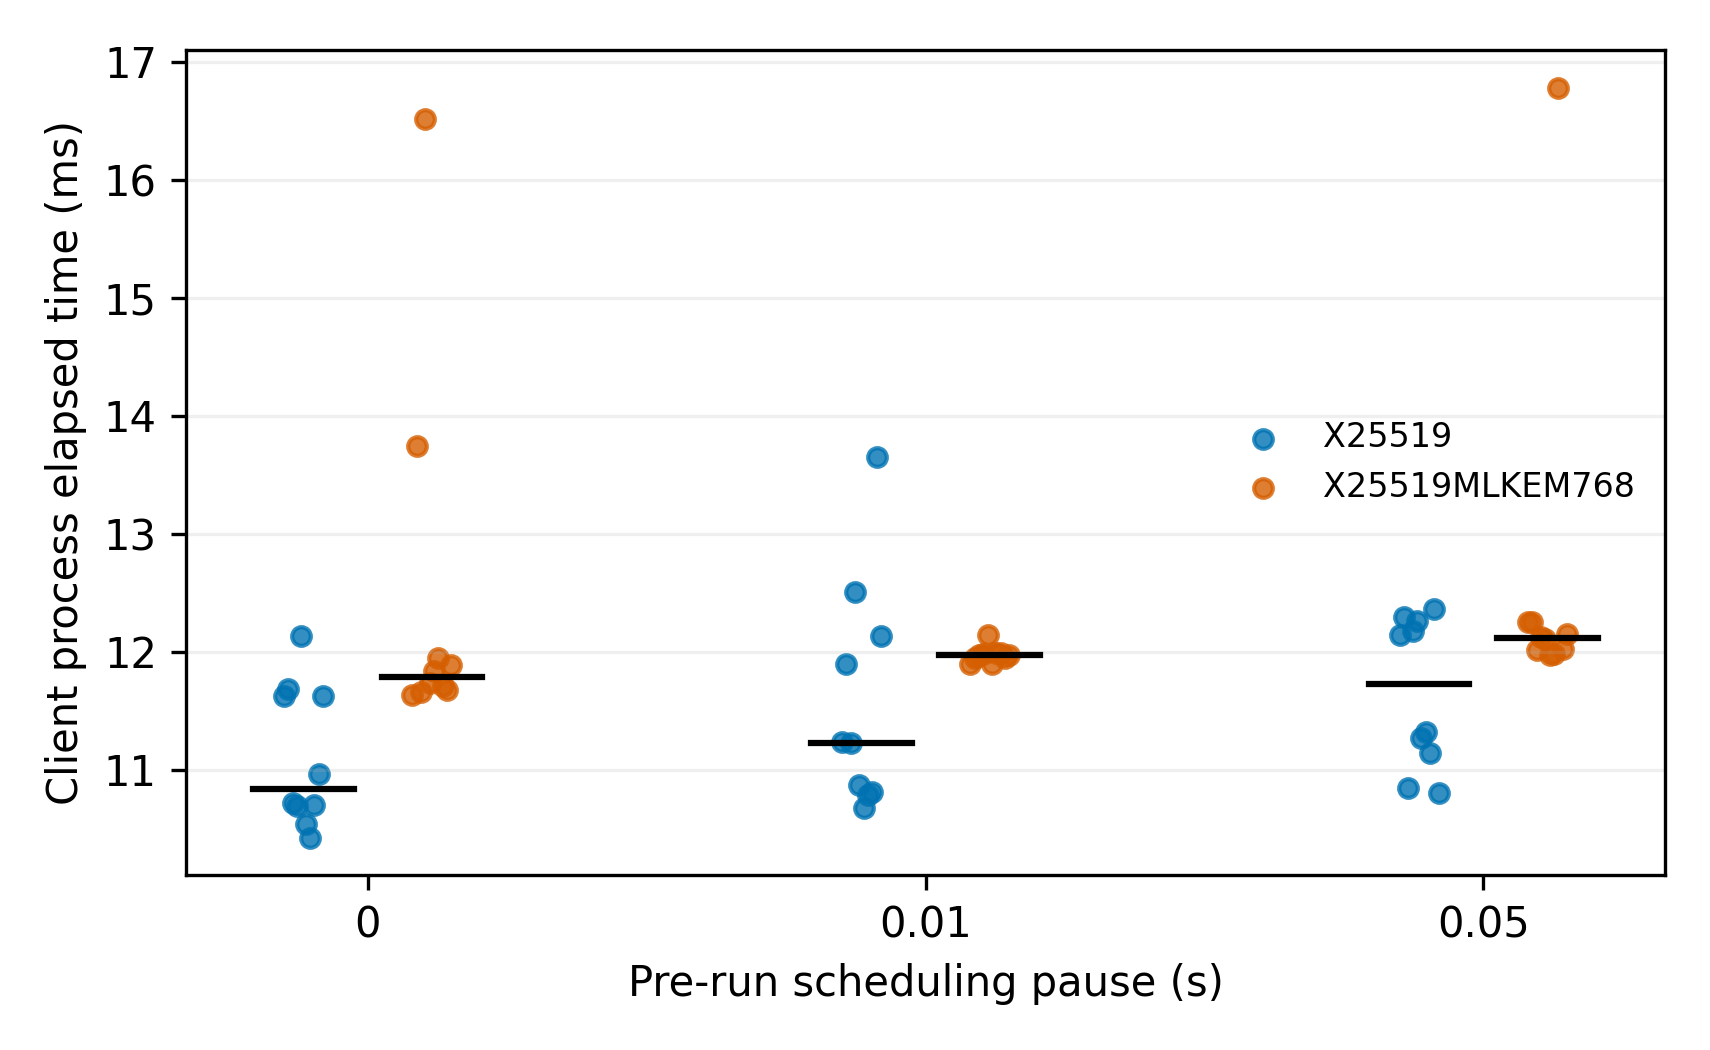

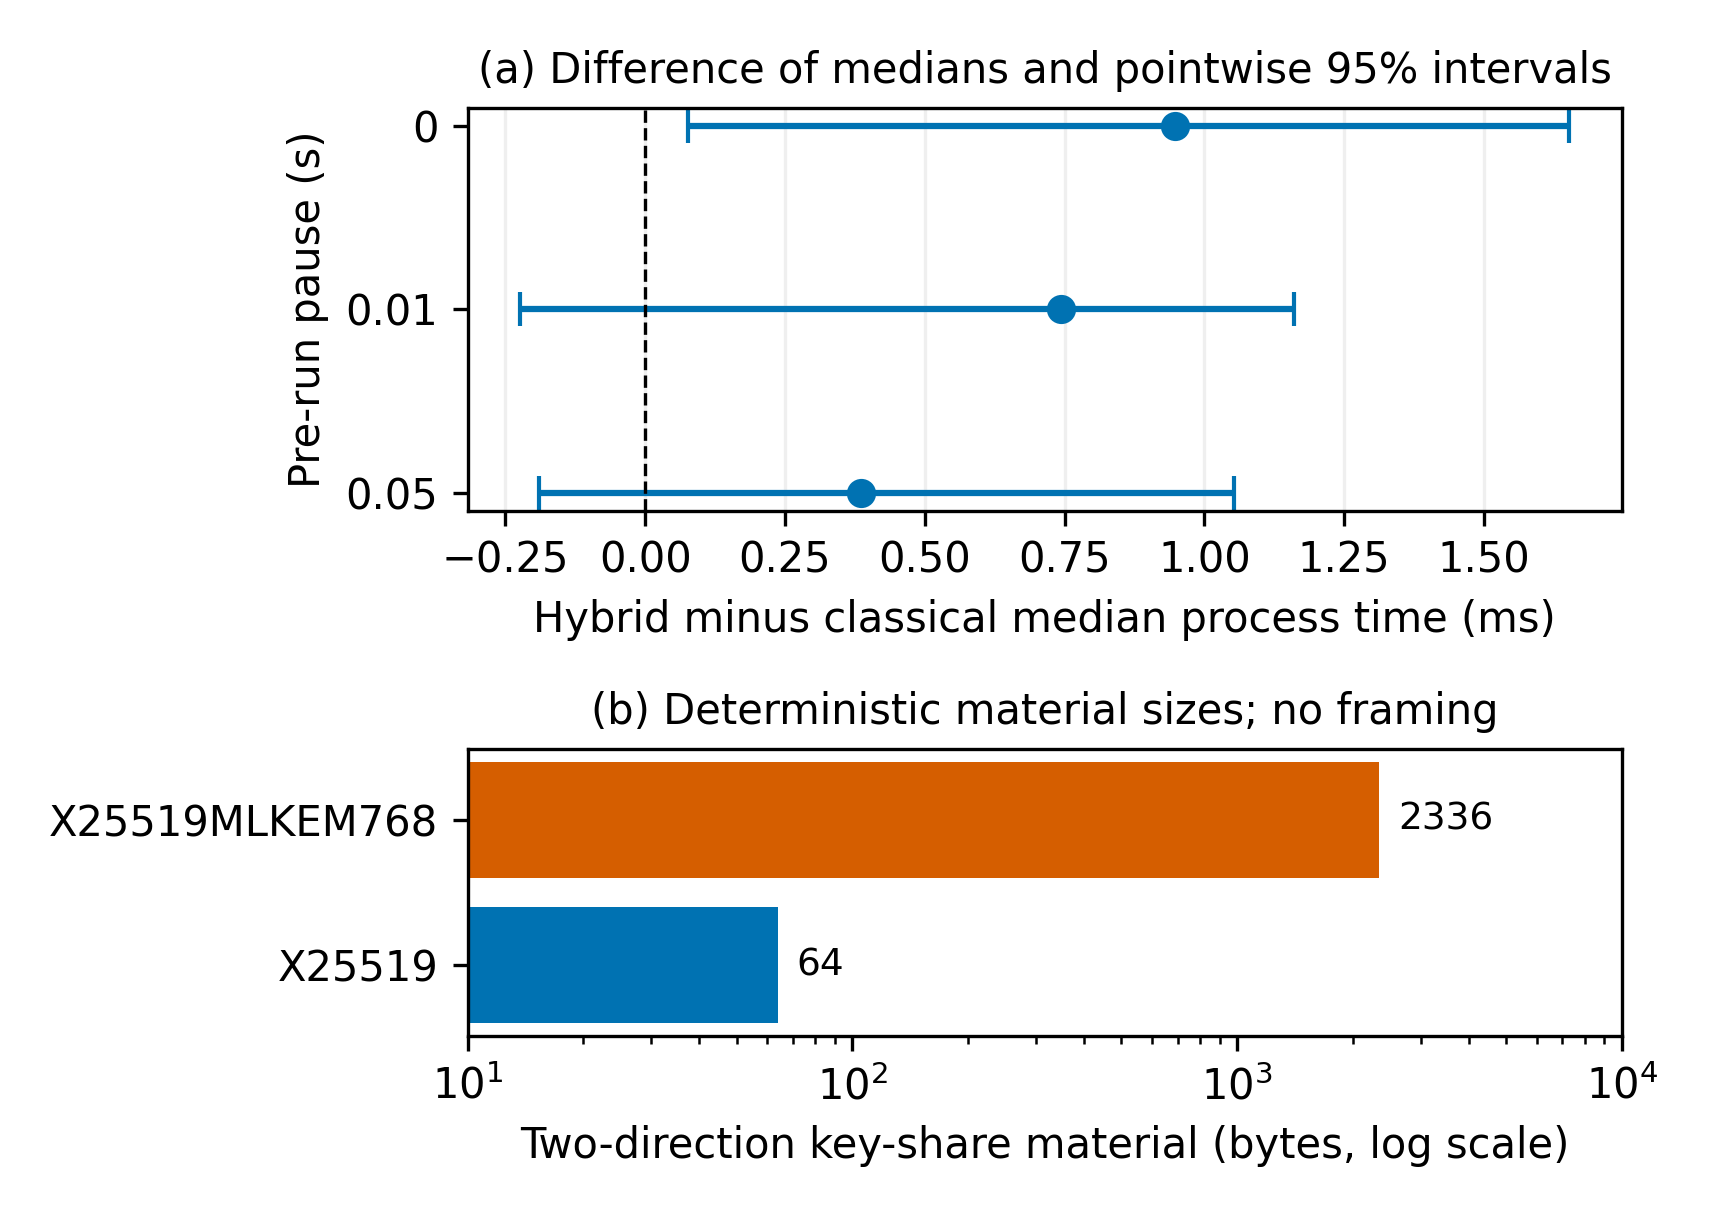

In [5]:
reanalyse.figures(raw,frames,ROOT/'results')
display(pd.read_csv(ROOT/'data/ukuran_key_share_statis.csv'))
try:
    from IPython.display import Image
    display(Image(filename=str(ROOT/'results/elapsed_points.png')))
    display(Image(filename=str(ROOT/'results/reviewer_figure3.png')))
except ImportError:
    print('Figures saved in',ROOT/'results')


## 5. Optional observer-off/on and internal-handshake collection

Set `RUN_NEW_SESSION=True` and execute this section on **one** independently provisioned runtime. Download its export, disconnect/delete that runtime, provision another runtime, and repeat until at least three distinct sessions exist. Do not pool new observations with the 2026-10-24 archive.

Each temporal block randomizes X25519/off, X25519/on, X25519MLKEM768/off, and X25519MLKEM768/on. Both timing outcomes come from each fresh C client process: `handshake_ms` wraps `SSL_connect`; `process_ms` wraps launch through output collection. The internal interval excludes process startup and TCP connect. The external observer samples at approximately 1 ms; both states use the same completion mechanism. A fixed 256-byte HTTP response, certificate verification, requested-group check, full-session check, and incompatible-group rejection validate the path. Warmups stay outside the dataset.

On first use, the notebook builds OpenSSL 3.5.4 only when the installed executable lacks the hybrid group. The build downloads source and verifies the publisher SHA-256. GCC and standard Linux build tools must be available. This optional build can take several minutes.


In [6]:
fresh=None
if RUN_NEW_SESSION:
    from install_openssl import ensure_openssl
    from collect_controls import collect
    openssl,prefix=ensure_openssl(ROOT/'openssl_build')
    session_dir=ROOT/'fresh_session'
    fresh,manifest,fresh_summary=collect(session_dir,openssl=openssl,blocks=BLOCKS,prefix=prefix)
    display(fresh_summary)
    print('One session only:',manifest['session_id'])
    print('CPU:',manifest['cpu_model'])
    print('Runtime fingerprint:',manifest['runtime_fingerprint'])
else:
    print('Fresh collection disabled. No new experimental outcomes are claimed.')


Fresh collection disabled. No new experimental outcomes are claimed.


## 6. Verify independent sessions before aggregation

Runtime fingerprints combine the boot identifier with hostname. A different label alone does not pass. Distinct fingerprints are a documentation check, not proof of statistically independent infrastructure. Keep each session’s group/observer summaries separate. A full study should predefine block-level resampling within sessions and session-level replication; the old session’s ten unblocked observations do not become new blocks.


In [7]:
SESSION_FOLDERS=[]  # Add downloaded/extracted session folders from >=3 distinct runtimes.
if SESSION_FOLDERS:
    from collect_controls import require_independent_sessions
    manifests=require_independent_sessions(SESSION_FOLDERS)
    for folder,m in zip(SESSION_FOLDERS,manifests):
        print('SESSION',m['session_id'])
        display(pd.read_csv(Path(folder)/'fresh_medians.csv'))
else:
    print('Three-session replication is pending; no cross-session inference is produced.')


Three-session replication is pending; no cross-session inference is produced.


## 7. Export sanitized results and code

The export excludes build directories, server private keys, and private logs. It contains data, executable analysis, provenance, and checksum metadata. The verified archive package is now public in the repository linked above. Register a persistent release identifier separately. New exports require their own version and verification before public release; this notebook does not mint a DOI.


In [8]:
import zipfile
export=ROOT/'TLS_PQC_Reviewer_Reproducibility.zip'
selected=[p for p in ROOT.rglob('*') if p.is_file() and not any(x in p.parts for x in ['openssl_build','build','__pycache__']) and p.suffix not in ['.key','.zip'] and p.name != 'checksums.json' and not p.name.endswith('_private.log')]
checksums={p.relative_to(ROOT).as_posix():hashlib.sha256(p.read_bytes()).hexdigest() for p in selected}
(ROOT/'checksums.json').write_text(json.dumps(checksums,indent=2))
with zipfile.ZipFile(export,'w',zipfile.ZIP_DEFLATED) as archive:
    for p in selected+[ROOT/'checksums.json']:
        archive.write(p,p.relative_to(ROOT))
print('Export prepared:',export)
try:
    from google.colab import files
    files.download(str(export))
except ImportError:
    print('Open the export from the local output folder.')


Export prepared: /content/tls_pqc_reviewer/TLS_PQC_Reviewer_Reproducibility.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Publish Code and Results to GitHub

Below, we provide the steps to configure your Git environment and push the verified, published reproducibility bundle directly to your GitHub repository.

## Interpretation and submission status

- The archived comparison is a single-session preliminary observation.
- Observer perturbation cannot be estimated retrospectively from the original records.
- Two principal intervals include zero; no trend across pauses is established.
- The optional collector supplies a testable future protocol, not fabricated replacement measurements.
- The archive package is public. Complete independent-session collection and persistent-identifier registration before stating those remaining reviewer requests are fully resolved.

The manuscript RIS file provides the verified published literature. Principal methodological sources include Efron and Narasimhan (2020), DOI10.1080/10618600.2020.1714633; Ho et al. (2019), DOI10.1038/s41592-019-0470-3; and current TLS evaluations documented in the manuscript.
